# Magic State Verification — Qublitz 2026 Theory / Algorithms Challenge

**Question:** given copies of an unknown single-qubit state $\rho$, how well can we tell whether it is the magic state
$|T\rangle = \cos\frac{\pi}{8}|0\rangle + \sin\frac{\pi}{8}|1\rangle$, using as few measurements as possible?

Magic states let a fault-tolerant quantum computer perform non-Clifford gates, which Clifford gates alone cannot provide [1]. The challenge is inspired by Google Quantum AI's work on magic-state cultivation [2].

This notebook solves all four levels. Each level has the same structure:

1. **Idea**: what we're doing and why, in plain language.
2. **Mechanism**: the math that makes it work.
3. **Code**: the algorithm itself.
4. **Experiments**: evidence that it works, and where it breaks.
5. **Takeaways**: how to read the results.

| Level | Goal | Our method |
|---|---|---|
| 1 | Reconstruct $\rho$ | Pauli tomography + projection onto the Bloch ball [3] |
| 2 | Estimate $F_T$ | Measure **only X and Z** (Y carries no information about $F_T$) [4] |
| 3 | Noisy readout | Calibrate on $\|0\rangle,\|1\rangle$, invert the readout map, propagate calibration error |
| 4 | Certify $F_T \ge 0.95$ | Reduce everything to **one biased coin**, then an **anytime-valid confidence sequence** [6–9] that is safe to check after every batch of shots |
| Bonus | Real hardware | The same estimators, unchanged, on single-shot data from an IQM quantum computer via Resonance [10, 11] |

**How to run:** Python 3.11 with `numpy`, `scipy`, `matplotlib`. Run all cells top to bottom (about 1–2 minutes). All randomness is seeded, so results are reproducible. The optional bonus section at the end also needs `qiskit`, `qiskit-aer` and `iqm-client` (see `requirements.txt`). By default it runs on a local noise model (or on saved hardware data, if present) and uses no Resonance credits.

## 0. Background: the Bloch sphere and the fidelity formula

Any single-qubit state can be written using its **Bloch vector** $\vec r = (r_x, r_y, r_z)$, with $|\vec r| \le 1$:

$$\rho = \tfrac12\left(I + r_x X + r_y Y + r_z Z\right), \qquad r_P = \mathrm{Tr}(\rho P) = \langle P \rangle .$$

- Pure states sit **on** the sphere ($|\vec r| = 1$); mixed (noisy) states sit **inside** it; the center is pure noise.
- Each component is the **average outcome** of measuring that Pauli, with outcomes $\pm 1$. So measuring $X$ many times and averaging the $\pm1$ results estimates $r_x$.

**The target.** $|T\rangle = \cos\frac\pi8|0\rangle + \sin\frac\pi8|1\rangle$ is the point on the sphere tilted $45^\circ$ from $+Z$ toward $+X$. This is the X/Z-plane convention from the Google cultivation work [2], and it is Clifford-equivalent to the usual $T$-type magic state [1]:

$$\vec n_T = \left(\tfrac{1}{\sqrt2},\, 0,\, \tfrac{1}{\sqrt2}\right).$$

**Fidelity.** Because $|T\rangle\langle T| = \frac12(I + \vec n_T\cdot\vec\sigma)$ and $\mathrm{Tr}(\sigma_i\sigma_j) = 2\delta_{ij}$,

$$F_T = \langle T|\rho|T\rangle = \tfrac12\left(1 + \vec r\cdot\vec n_T\right) = \tfrac12\left(1 + \frac{r_x + r_z}{\sqrt2}\right).$$

**Geometric picture:** $F_T$ only cares about how far the state's arrow points **along the $T$ direction**. This one fact drives most of the design choices below:
- $r_y$ does not appear at all, so measuring $Y$ is wasted effort for fidelity (Level 2).
- A white-noise-damaged state $\vec r = (1-p)\,\vec n_T$ has $F_T = 1 - p/2$.
- A pure state tilted by angle $\delta$ away from $|T\rangle$ has $F_T = \cos^2(\delta/2)$. Different errors can give the same $F_T$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import betaln

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(2026)   # one seeded generator -> reproducible notebook
SQ2 = np.sqrt(2)

# Pauli matrices
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
PAULIS = {"X": X, "Y": Y, "Z": Z}

# Target magic state |T> = cos(pi/8)|0> + sin(pi/8)|1>, Bloch vector (1/sqrt2, 0, 1/sqrt2)
T_KET = np.array([np.cos(np.pi / 8), np.sin(np.pi / 8)], dtype=complex)
N_T = np.array([1 / SQ2, 0.0, 1 / SQ2])


def rho_from_bloch(r):
    return 0.5 * (I2 + r[0] * X + r[1] * Y + r[2] * Z)


def bloch_from_rho(rho):
    return np.real([np.trace(rho @ P) for P in (X, Y, Z)])


def fidelity_from_xz(rx, rz):
    # F_T = (1 + (r_x + r_z)/sqrt2) / 2
    return 0.5 * (1 + (rx + rz) / SQ2)

### Test states and the simulated lab

To grade our algorithms we need states whose true fidelity we know. The **estimators never see these states**. They only get a `Lab` object that hands back measurement outcomes, the way a real experiment would. The true state is used **only afterwards**, to score the answer (`true_fidelity`, `trace_distance`).

**Error families used throughout:**

| Name | What it models | Bloch vector | $F_T$ |
|---|---|---|---|
| `depolarized_T(F)` | random (incoherent) noise | $(1-p)\,\vec n_T$ | $1 - p/2$ |
| `tilted_T(F)` | coherent over-rotation, still pure | $\vec n_T$ rotated by $\delta$ in the X–Z plane | $\cos^2(\delta/2)$ |
| `noisy_T(...)` | any mix, including rotation out of plane into $Y$ | general | general |
| `random_state` | arbitrary unknown state | uniform in the ball (or on the sphere) | anything |

**Measurement simulation** (from the challenge): measuring Pauli $P$ gives $+1$ with probability $\frac{1+\mathrm{Tr}(\rho P)}{2}$, independently for every shot.
The `Lab` can also add **readout errors** (Level 3) and measure **known reference states** for calibration.

In [2]:
# generate error families
def noisy_T(depolarizing=0.0, tilt=0.0, out_of_plane=0.0):
    # |T>, rotated by `tilt` (rad) in the X-Z plane and `out_of_plane` (rad) toward Y, then shrunk by (1 - depolarizing)
    theta = np.pi / 4 + tilt
    direction = np.array([np.sin(theta) * np.cos(out_of_plane),
                          np.sin(theta) * np.sin(out_of_plane),
                          np.cos(theta)])
    return rho_from_bloch((1 - depolarizing) * direction)


def depolarized_T(F):
    # white noise chosen so that F_T = F exactly
    return noisy_T(depolarizing=2 * (1 - F))


def tilted_T(F):
    # a PURE state, coherently rotated away from |T> just enough that F_T = F
    return noisy_T(tilt=2 * np.arccos(np.sqrt(F)))


def random_state(rng, pure=False):
    v = rng.normal(size=3)
    v /= np.linalg.norm(v)
    radius = 1.0 if pure else rng.random() ** (1 / 3)   # uniform inside the Bloch ball
    return rho_from_bloch(radius * v)


# ---- grading helpers: used ONLY after an estimate is made, to score it ----
def true_fidelity(rho):
    return float(np.real(T_KET.conj() @ rho @ T_KET))


def trace_distance(rho, sigma):
    return 0.5 * np.sum(np.abs(np.linalg.eigvalsh(rho - sigma)))


class Lab:
    # Simulated experiment. Prepares fresh copies of a hidden state and measures them.
    # Estimators only call the public methods, so they can only learn about the state through outcomes.
    #
    # Readout model (Level 3): every Pauli measurement is "rotate the basis, then read out in Z",
    # so ONE classical readout channel applies to X, Y and Z alike:
    #   e0 = P(report -1 | true outcome +1)    (a |0> misread as 1)
    #   e1 = P(report +1 | true outcome -1)    (a |1> misread as 0)

    def __init__(self, rho, readout_error=(0.0, 0.0), reference_prep_error=0.0, rng=None):
        self._rho = rho
        self._e0, self._e1 = readout_error
        self._ref_err = reference_prep_error
        self._rng = rng if rng is not None else np.random.default_rng()
        self.shots_used = 0

    def _sample(self, p_plus, shots):
        p_report_plus = (1 - self._e0) * p_plus + self._e1 * (1 - p_plus)
        self.shots_used += shots
        return np.where(self._rng.random(shots) < p_report_plus, 1, -1)

    def measure(self, basis, shots):
        # measure `shots` amount of fresh copies in Pauli basis 'X', 'Y' or 'Z'; returns an array of +1/-1
        p_plus = (1 + np.real(np.trace(self._rho @ PAULIS[basis]))) / 2
        return self._sample(p_plus, shots)

    def measure_reference(self, label, shots):
        # calibration: prepare the KNOWN state |0> (label '0') or |1> (label '1') and measure Z.
        # reference_prep_error > 0 models imperfectly prepared references (a failure mode in Level 3)
        p_plus = 1 - self._ref_err if label == "0" else self._ref_err
        return self._sample(p_plus, shots)

    def measure_T_basis(self, shots):
        # NOT a Pauli measurement: +1 means "found |T>". Used only as a point of comparison.
        p_plus = np.real(T_KET.conj() @ self._rho @ T_KET)
        return self._sample(p_plus, shots)


# Sanity checks: the fidelity formula matches <T|rho|T>, and the simulated lab reproduces Tr(rho P)
for _ in range(1000):
    s = random_state(rng)
    assert np.isclose(true_fidelity(s), fidelity_from_xz(*bloch_from_rho(s)[[0, 2]]))
for F in (0.99, 0.9, 0.7):
    assert np.isclose(true_fidelity(depolarized_T(F)), F) and np.isclose(true_fidelity(tilted_T(F)), F)
check = Lab(depolarized_T(0.9), rng=rng)
print("formula checks passed")
print("Bloch vector of depolarized_T(0.9):", bloch_from_rho(depolarized_T(0.9)))
print("<X> from 200k simulated shots     :", check.measure("X", 200_000).mean().round(4))

formula checks passed
Bloch vector of depolarized_T(0.9): [0.5657 0.     0.5657]
<X> from 200k simulated shots     : 0.5703


---
# Level 1: Reconstruct the state (tomography)

### Idea
A qubit has three unknown numbers, $(r_x, r_y, r_z)$. Each is the average of $\pm1$ outcomes when measuring that Pauli. So:

1. Measure $X$, $Y$ and $Z$, $n$ shots each.
2. Average each to get $\hat r_P = \frac{N_+ - N_-}{n}$.
3. Plug the estimates into $\hat\rho = \frac12(I + \hat r_x X + \hat r_y Y + \hat r_z Z)$.

This is called **linear-inversion tomography**.

### Mechanism and the physicality problem
Each $\hat r_P$ is unbiased with variance $\frac{1 - r_P^2}{n}$, so the error shrinks like $1/\sqrt n$.
However, the three estimates are noisy **independently**, and nothing stops the estimated vector from landing **outside** the Bloch ball ($|\hat{\vec r}| > 1$). That corresponds to a "density matrix" with a **negative eigenvalue** (eigenvalues are $\frac{1 \pm |\vec r|}{2}$), which is not a physical state.

**Fix:** if $|\hat{\vec r}| > 1$, shrink it back to the surface: $\hat{\vec r} \to \hat{\vec r} / |\hat{\vec r}|$. Why this is the right fix:
- For a qubit, Hilbert–Schmidt distance between states equals Euclidean distance between Bloch vectors (divided by $\sqrt2$). So the radial projection gives the **closest physical density matrix**. This is the same answer as the eigenvalue-clipping method of Smolin, Gambetta & Smith (2012) [3].
- Projecting onto a convex set that contains the truth **never moves the estimate farther from the truth**, so the fix can only help.

The result is Hermitian by construction, has trace 1, and has eigenvalues $\frac{1\pm|\hat{\vec r}|}{2} \ge 0$.

In [3]:
def reconstruct_state(lab, shots_per_basis):
    # Level 1: Pauli tomography -> physical density matrix
    r_raw = np.array([lab.measure(b, shots_per_basis).mean() for b in "XYZ"])
    norm = np.linalg.norm(r_raw)
    r_hat = r_raw / norm if norm > 1 else r_raw                      # project onto the Bloch ball if needed
    stderr = np.sqrt(np.clip(1 - r_raw**2, 0, None) / shots_per_basis)   # 1-sigma error per component
    return rho_from_bloch(r_hat), {"r_raw": r_raw, "r_hat": r_hat, "stderr": stderr, "projected": norm > 1}


# --- Example: a generic noisy state (rotated, partly out of plane, partly depolarized) ---
rho_true = noisy_T(depolarizing=0.2, tilt=0.3, out_of_plane=0.5)
lab = Lab(rho_true, rng=rng)
rho_hat, info = reconstruct_state(lab, shots_per_basis=1000)

print(f"shots used: {lab.shots_used}  (1000 per basis)\n")
print("true Bloch vector     :", bloch_from_rho(rho_true))
print("estimated Bloch vector:", info["r_hat"], " +/-", info["stderr"])
print("\ntrue rho:\n", rho_true, "\n\nestimated rho:\n", rho_hat)
print("\nphysical? Hermitian:", np.allclose(rho_hat, rho_hat.conj().T),
      "| trace:", round(np.trace(rho_hat).real, 6),
      "| eigenvalues:", np.linalg.eigvalsh(rho_hat))
print("trace distance to the truth:", round(trace_distance(rho_true, rho_hat), 4))

shots used: 3000  (1000 per basis)

true Bloch vector     : [0.621  0.3392 0.3732]
estimated Bloch vector: [0.626 0.328 0.374]  +/- [0.0247 0.0299 0.0293]

true rho:
 [[0.6866+0.j     0.3105-0.1696j]
 [0.3105+0.1696j 0.3134+0.j    ]] 

estimated rho:
 [[0.687+0.j    0.313-0.164j]
 [0.313+0.164j 0.313+0.j   ]]

physical? Hermitian: True | trace: 1.0 | eigenvalues: [0.1002 0.8998]
trace distance to the truth: 0.0062


### Experiment 1: how error shrinks with shots, and how often the raw estimate is unphysical

We reconstruct three kinds of states 300 times each, at budgets from 10 to 10,000 shots per basis:
- the **pure** magic state $|T\rangle$,
- a **slightly noisy** magic state ($F_T = 0.95$, $|\vec r| = 0.9$),
- a **very mixed** state ($|\vec r| = 0.3$).

**Error metric:** the trace distance $D(\rho,\hat\rho) = \frac12|\vec r - \hat{\vec r}|$. It is the maximum difference in the probability of any measurement outcome between the true and estimated states.

**Panels:**
- **Left:** error against shots. Filled circles are our projected estimate, hollow squares are the raw linear-inversion estimate, and the dotted line is the theory $\mathrm{RMS}(D) \approx \frac12\sqrt{\sum_P (1 - r_P^2)/n}$. The circles and squares nearly overlap on a log scale, so:
- **Middle:** the difference made visible, as the percentage by which projection reduces the error. Above 0 means projection helped.
- **Right:** how often the raw estimate is unphysical ($|\hat{\vec r}| > 1$) and needs projecting.

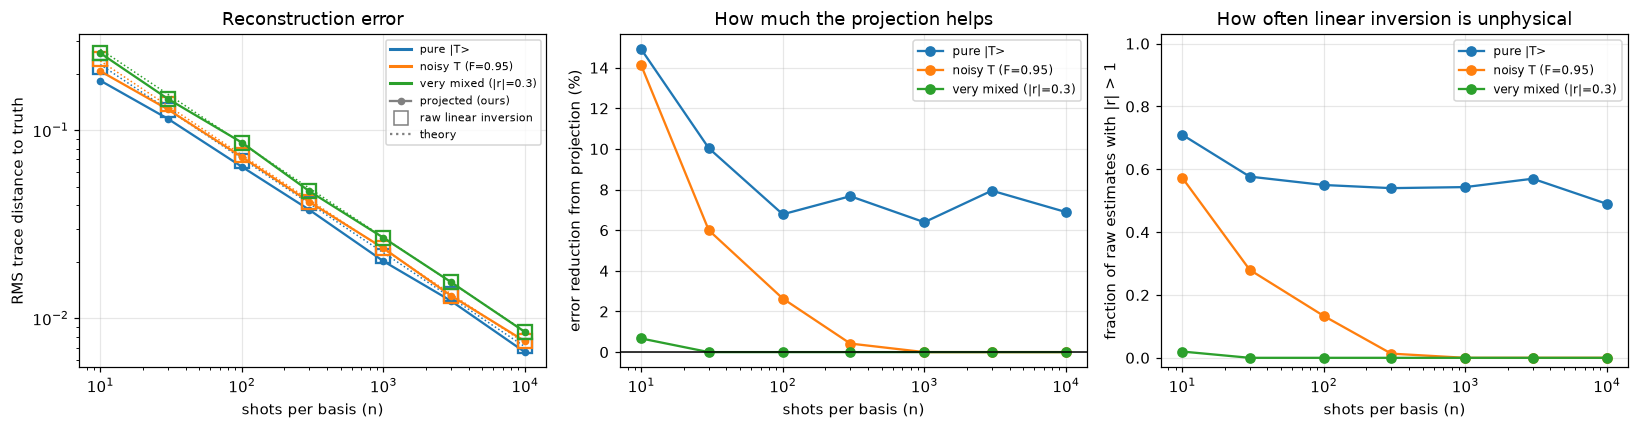

RMS error reduction from projection (%):
  pure |T>               n=10: 14.9  n=30: 10.0  n=100:  6.8  n=300:  7.7  n=1000:  6.4  n=3000:  7.9  n=10000:  6.9
  noisy T (F=0.95)       n=10: 14.1  n=30:  6.0  n=100:  2.6  n=300:  0.4  n=1000:  0.0  n=3000:  0.0  n=10000:  0.0
  very mixed (|r|=0.3)   n=10:  0.7  n=30:  0.0  n=100:  0.0  n=300:  0.0  n=1000:  0.0  n=3000:  0.0  n=10000:  0.0


In [4]:
shots_grid = np.array([10, 30, 100, 300, 1000, 3000, 10000])
L1_STATES = {
    "pure |T>": depolarized_T(1.0),
    "noisy T (F=0.95)": depolarized_T(0.95),
    "very mixed (|r|=0.3)": rho_from_bloch(0.3 * np.array([0.6, 0.0, 0.8])),
}
TRIALS = 300

from matplotlib.lines import Line2D

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))
gains = {}
for k, (name, rho) in enumerate(L1_STATES.items()):
    r_true = bloch_from_rho(rho)
    rms_raw, rms_proj, unphysical = [], [], []
    for n in shots_grid:
        d_raw, d_proj, proj = [], [], []
        for _ in range(TRIALS):
            _, inf = reconstruct_state(Lab(rho, rng=rng), n)
            d_raw.append(np.linalg.norm(inf["r_raw"] - r_true) / 2)
            d_proj.append(np.linalg.norm(inf["r_hat"] - r_true) / 2)
            proj.append(inf["projected"])
        rms_raw.append(np.sqrt(np.mean(np.square(d_raw))))
        rms_proj.append(np.sqrt(np.mean(np.square(d_proj))))
        unphysical.append(np.mean(proj))
    theory = 0.5 * np.sqrt(np.sum(1 - r_true**2) / shots_grid)
    rms_raw, rms_proj = np.array(rms_raw), np.array(rms_proj)
    gains[name] = 100 * (1 - rms_proj / rms_raw)
    ax1.loglog(shots_grid, theory, ":", color=f"C{k}", lw=1)
    ax1.loglog(shots_grid, rms_raw, "s", color=f"C{k}", ms=9, mfc="none", mew=1.5)
    ax1.loglog(shots_grid, rms_proj, "o-", color=f"C{k}", ms=4)
    ax2.semilogx(shots_grid, gains[name], "o-", color=f"C{k}", label=name)
    ax3.semilogx(shots_grid, unphysical, "o-", color=f"C{k}", label=name)

# legend for the left panel: colors = states, marker styles = estimator
handles = [Line2D([], [], color=f"C{k}", lw=2, label=name) for k, name in enumerate(L1_STATES)]
handles += [Line2D([], [], color="gray", marker="o", ms=4, label="projected (ours)"),
            Line2D([], [], color="gray", marker="s", ms=9, mfc="none", ls="none", label="raw linear inversion"),
            Line2D([], [], color="gray", ls=":", label="theory")]
ax1.legend(handles=handles, fontsize=7)
ax1.set(xlabel="shots per basis (n)", ylabel="RMS trace distance to truth", title="Reconstruction error")
ax2.axhline(0, color="k", lw=1)
ax2.set(xlabel="shots per basis (n)", ylabel="error reduction from projection (%)",
        title="How much the projection helps")
ax2.legend(fontsize=8)
ax3.set(xlabel="shots per basis (n)", ylabel="fraction of raw estimates with |r| > 1",
        title="How often linear inversion is unphysical", ylim=(-0.03, 1.03))
ax3.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("RMS error reduction from projection (%):")
for name, g in gains.items():
    print(f"  {name:22s}", "  ".join(f"n={n}: {v:4.1f}" for n, v in zip(shots_grid, g)))

### Level 1 takeaways
- **Error scales as $1/\sqrt{n}$** (slope $-\tfrac12$ on the log-log plot) and matches the theory line, so the estimator behaves as expected. To halve the error you need **4× the shots**.
- **A pure state's raw estimate is unphysical about half the time, at every budget** (71% at 10 shots per basis, then 49–58%). The reason: the true vector sits on the sphere's surface, and random errors push it outward about half the time. More shots don't fix this; only the projection does. A **near-pure** state ($|\vec r| = 0.9$) is also often unphysical at small budgets (57% at 10 shots, 13% at 100), but almost never from about 300 shots per basis on, once the errors are smaller than its 0.1 gap to the surface. The very mixed state sits deep inside the ball and almost never needs fixing.
- The **projection only ever helps** (middle panel, always ≥ 0%), and how much depends on how pure the state is:
  - **pure $|T\rangle$:** about 15% less error at 10 shots per basis, settling at a **steady 6–8% from 100 shots per basis on**. Because about half the estimates are always unphysical, the projection keeps helping no matter how many shots you take.
  - **noisy $T$ ($|\vec r| = 0.9$):** helps a lot at small budgets (14% at 10 shots), then fades to 0. Once the error is smaller than the 0.1 gap to the sphere's surface, the estimate stops leaving the ball.
  - **very mixed state:** essentially no effect, since the estimate is almost never outside the ball.
- **Inefficiency for our goal:** tomography spends a third of the budget on $Y$, which tells us nothing about $F_T$. Level 2 fixes that.

---
# Level 2: Estimate the fidelity directly

### Idea
We don't need the whole state, only the number $F_T = \frac12\left(1 + \frac{r_x + r_z}{\sqrt2}\right)$.
That depends on **only $r_x$ and $r_z$**. So we put **all** shots into $X$ and $Z$ (half each) and plug the averages into the formula. This is the "direct fidelity estimation" idea (Flammia & Liu 2011) [4]: only measure the Paulis that appear in the target state.

**Worked example from the challenge:** 100 X shots (84 up, 16 down) and 100 Z shots (85 up, 15 down) give
$\hat r_x = 0.68$, $\hat r_z = 0.70$ and $\hat F_T = \frac12\left(1 + \frac{1.38}{\sqrt2}\right) \approx 0.988$.

### Mechanism: why this is more efficient
For a budget of $N$ total shots, the variance of $\hat F_T$ is:

| Strategy | Shots | $\mathrm{Var}(\hat F_T)$ |
|---|---|---|
| Full tomography (X, Y, Z) | $N/3$ each | $\dfrac{3\,(2 - r_x^2 - r_z^2)}{8N}$ |
| **X & Z only (ours)** | $N/2$ each | $\dfrac{2 - r_x^2 - r_z^2}{4N}$ — **1.5× smaller** |
| $T$-basis measurement (not Pauli) | $N$ | $\dfrac{F_T(1-F_T)}{N}$ |

Equal X/Z split is optimal for states near $|T\rangle$, because $r_x \approx r_z$ makes the two variances equal.

**The non-Pauli reference row.** If we could measure directly in the basis $\{|T\rangle, |T^\perp\rangle\}$, each shot would be a coin that lands heads with probability exactly $F_T$. Near $F_T = 1$ that coin is almost deterministic, so its variance $F(1-F)$ approaches 0.
Pauli outcomes, by contrast, are **intrinsically random even for a perfect $|T\rangle$**: $X$ gives $+1$ only 85% of the time.
The catch is that rotating into the $T$ basis requires a non-Clifford rotation. In a fault-tolerant setting, that is exactly the expensive resource we are trying to verify. The challenge restricts us to Pauli measurements for this reason, so the $T$-basis appears **only as a benchmark**.

### Uncertainty
We report $\hat F_T \pm 1.96\,\mathrm{SE}$, where $\mathrm{SE} = \frac{1}{2\sqrt2}\sqrt{\frac{1-\hat r_x^2}{n_x} + \frac{1-\hat r_z^2}{n_z}}$ (normal approximation). The final estimate is clipped to $[0,1]$.

In [5]:
def estimate_fidelity(lab, total_shots, strategy="XZ"):
    # Level 2: estimate F_T with `total_shots` measurements. Returns (F_hat, standard_error).
    if strategy == "XZ":                       # our method
        nx = total_shots // 2
        nz = total_shots - nx
        rx, rz = lab.measure("X", nx).mean(), lab.measure("Z", nz).mean()
        F = fidelity_from_xz(rx, rz)
        se = np.sqrt((1 - rx**2) / nx + (1 - rz**2) / nz) / (2 * SQ2)
    elif strategy == "XYZ":                    # baseline: tomography first, then the formula
        n = total_shots // 3
        _, inf = reconstruct_state(lab, n)
        rx, _, rz = inf["r_hat"]
        F = fidelity_from_xz(rx, rz)
        se = np.sqrt((2 - rx**2 - rz**2) / n) / (2 * SQ2)
    elif strategy == "T-basis":                # non-Pauli benchmark
        F = (lab.measure_T_basis(total_shots) == 1).mean()
        se = np.sqrt(F * (1 - F) / total_shots)
    else:
        raise ValueError(strategy)
    return float(np.clip(F, 0, 1)), float(se)


def predicted_rmse(rho, N, strategy):
    # theory from the table above (uses the true state -> for plotting only)
    rx, _, rz = bloch_from_rho(rho)
    F = true_fidelity(rho)
    return {"XZ": np.sqrt((2 - rx**2 - rz**2) / (4 * N)),
            "XYZ": np.sqrt(3 * (2 - rx**2 - rz**2) / (8 * N)),
            "T-basis": np.sqrt(F * (1 - F) / N)}[strategy]


# The challenge's worked example
print("worked example: F_hat =", round(fidelity_from_xz((84 - 16) / 100, (85 - 15) / 100), 4))

# One run on a hidden state
rho_test = depolarized_T(0.95)
F_hat, se = estimate_fidelity(Lab(rho_test, rng=rng), 1000)
print(f"\none run, 1000 shots: F_hat = {F_hat:.4f} +/- {1.96 * se:.4f} (95% CI)   true F = {true_fidelity(rho_test):.4f}")

worked example: F_hat = 0.9879

one run, 1000 shots: F_hat = 0.9115 +/- 0.0356 (95% CI)   true F = 0.9500


### Experiment 2: same budget, three strategies

Test state: $F_T = 0.95$ (depolarized $|T\rangle$). We run 1,000 repeats at each budget.
- **Left:** RMSE against budget. Dots are simulation, dashed lines are theory.
- **Right:** the spread of estimates at the challenge's example budget of 200 shots.

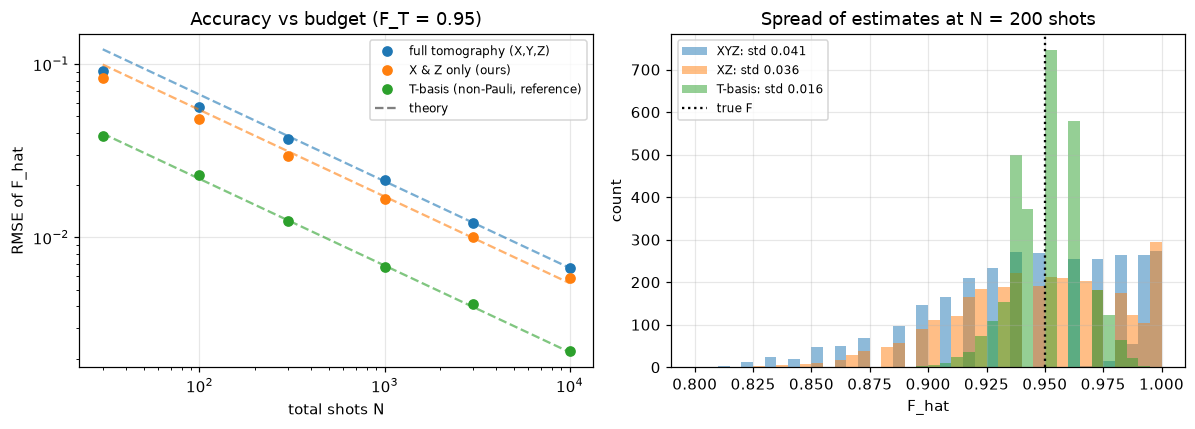

full tomography (X,Y,Z)     : shots for RMSE 0.01 ~    4462
X & Z only (ours)           : shots for RMSE 0.01 ~    2975
T-basis (non-Pauli, reference): shots for RMSE 0.01 ~     475


In [6]:
STRATS = ["XYZ", "XZ", "T-basis"]
LABELS = {"XYZ": "full tomography (X,Y,Z)", "XZ": "X & Z only (ours)", "T-basis": "T-basis (non-Pauli, reference)"}
budgets = np.array([30, 100, 300, 1000, 3000, 10000])
rho_test = depolarized_T(0.95)
F_true = true_fidelity(rho_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for k, s in enumerate(STRATS):
    rmse = [np.sqrt(np.mean([(estimate_fidelity(Lab(rho_test, rng=rng), N, s)[0] - F_true) ** 2 for _ in range(1000)]))
            for N in budgets]
    ax1.loglog(budgets, rmse, "o", color=f"C{k}", label=LABELS[s])
    ax1.loglog(budgets, [predicted_rmse(rho_test, N, s) for N in budgets], "--", color=f"C{k}", alpha=0.6)
    est = [estimate_fidelity(Lab(rho_test, rng=rng), 200, s)[0] for _ in range(3000)]
    ax2.hist(est, bins=np.linspace(0.8, 1.0, 41), alpha=0.5, color=f"C{k}",
             label=f"{s}: std {np.std(est):.3f}")
ax1.set(xlabel="total shots N", ylabel="RMSE of F_hat", title="Accuracy vs budget (F_T = 0.95)")
from matplotlib.lines import Line2D
handles, _ = ax1.get_legend_handles_labels()
handles.append(Line2D([], [], color="gray", ls="--", label="theory"))
ax1.legend(handles=handles, fontsize=8)
ax2.axvline(F_true, color="k", ls=":", label="true F")
ax2.set(xlabel="F_hat", ylabel="count", title="Spread of estimates at N = 200 shots")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

for s in ["XYZ", "XZ", "T-basis"]:
    print(f"{LABELS[s]:28s}: shots for RMSE 0.01 ~ {predicted_rmse(rho_test, 1, s)**2 / 0.01**2:7.0f}")

### Experiment 3: many different states, and whether the error bars are honest

An estimator should work on **any** state, not one favorable example. We draw 300 states:
- half random (anywhere in the Bloch ball),
- half "realistic" noisy magic states (random tilt, out-of-plane rotation and depolarization).

We estimate each one with 1,000 shots.

- **Left:** estimated against true fidelity, with 95% error bars.
- **Right:** **coverage**, the fraction of runs whose 95% interval actually contains the true value. It should be about 95%. We check this across budgets.

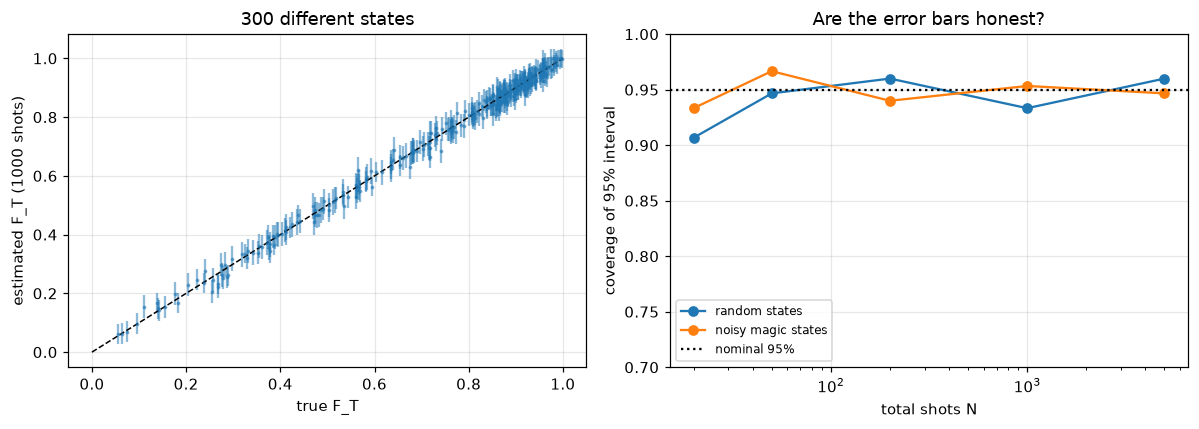

RMSE over all 300 states at N=1000: 0.0183


In [7]:
def realistic_noisy_T(rng):
    return noisy_T(depolarizing=rng.uniform(0, 0.3), tilt=rng.normal(0, 0.3), out_of_plane=rng.normal(0, 0.3))

states = [random_state(rng) for _ in range(150)] + [realistic_noisy_T(rng) for _ in range(150)]
truth = np.array([true_fidelity(s) for s in states])
results = np.array([estimate_fidelity(Lab(s, rng=rng), 1000) for s in states])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.errorbar(truth, results[:, 0], yerr=1.96 * results[:, 1], fmt=".", alpha=0.5, ms=3)
ax1.plot([0, 1], [0, 1], "k--", lw=1)
ax1.set(xlabel="true F_T", ylabel="estimated F_T (1000 shots)", title="300 different states")

cov_budgets = [20, 50, 200, 1000, 5000]
for label, pool in [("random states", states[:150]), ("noisy magic states", states[150:])]:
    cov = []
    for N in cov_budgets:
        hits = 0
        for s in pool:
            F, se = estimate_fidelity(Lab(s, rng=rng), N)
            hits += abs(F - true_fidelity(s)) <= 1.96 * se
        cov.append(hits / len(pool))
    ax2.semilogx(cov_budgets, cov, "o-", label=label)
ax2.axhline(0.95, color="k", ls=":", label="nominal 95%")
ax2.set(xlabel="total shots N", ylabel="coverage of 95% interval", ylim=(0.7, 1.0), title="Are the error bars honest?")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"RMSE over all 300 states at N=1000: {np.sqrt(np.mean((results[:, 0] - truth) ** 2)):.4f}")

### Level 2 takeaways
- **Measure only what you need.** Dropping $Y$ gives the same accuracy with **1.5× fewer shots** than tomography, and simulation matches theory.
- **Precision is expensive:** RMSE $\approx 0.55/\sqrt N$ near $|T\rangle$. About 3,000 shots give ±0.01. To tell 0.95 apart from 0.96 you need thousands of shots, which motivates Level 4.
- **Why Pauli shots are so costly:** even a perfect $|T\rangle$ gives random $\pm1$ outcomes in $X$ and $Z$. Each Pauli shot carries little information about $F_T$. The (non-Pauli) $T$-basis measurement would be about 6× more efficient at $F_T = 0.95$, but it requires the very non-Clifford operation we are testing.
- **The error bars are honest:** coverage stays close to 95% from about 50 shots upward, for random and magic-like states alike. **Failure mode:** at very small budgets (about 20 shots), the normal approximation starts to break and coverage slips to about 91–93%. If every $X$ shot happens to give $+1$, the estimated SE even collapses to 0. Level 4 uses exact methods that don't rely on this approximation.
- **Clipping to [0, 1]** is required for a valid output, but it slightly biases estimates for states very close to $F_T = 1$.

---
# Level 3: Imperfect measurements (readout errors)

### Idea
Real detectors sometimes report the wrong answer. If we ignore that, every $\langle P\rangle$ we measure is **systematically** wrong, and no number of shots removes the bias. Instead we:
1. **learn** the detector's error rates by measuring states we know (calibration),
2. **undo** their effect mathematically.

### Readout error model
On hardware, measuring $X$ or $Y$ means **rotating the qubit and then measuring $Z$**, so a single physical readout channel affects all three bases. We allow it to be **asymmetric**:

$$e_0 = P(\text{read } 1 \mid \text{was } 0), \qquad e_1 = P(\text{read } 0 \mid \text{was } 1).$$

Typically $e_1 > e_0$, because an excited qubit can decay during readout. We use $e_0 = 3\%$ and $e_1 = 5\%$.

Working through the probabilities gives an **affine distortion** of every expectation value:

$$\langle P \rangle_\text{obs} = \eta\,\langle P\rangle_\text{true} + \beta, \qquad \eta = 1 - e_0 - e_1,\quad \beta = e_1 - e_0 .$$

- $\eta < 1$ shrinks the Bloch vector toward the center.
- $\beta$ shifts all outcomes toward $+1$ or $-1$.
- For symmetric errors ($e_0 = e_1 = \epsilon$), $\beta = 0$ and $\eta = 1 - 2\epsilon$. That is the challenge's example model.

### Calibration and correction
Prepare $|0\rangle$ (where $\langle Z\rangle = +1$) and $|1\rangle$ (where $\langle Z\rangle = -1$), and measure each $n_c$ times:

$$c_0 = \eta + \beta, \quad c_1 = -\eta + \beta \;\;\Rightarrow\;\; \hat\eta = \frac{\hat c_0 - \hat c_1}{2},\quad \hat\beta = \frac{\hat c_0 + \hat c_1}{2},\quad \hat r_P = \frac{\hat{\langle P\rangle}_\text{obs} - \hat\beta}{\hat\eta}.$$

Then $\hat F_T = \frac12 + \frac{\hat r_x + \hat r_z}{2\sqrt2}$, as before.

### Handling calibration uncertainty
$\hat\eta$ and $\hat\beta$ are **themselves estimated from finite shots**. Their noise feeds into $\hat F_T$. We propagate it with the **delta method**: a first-order Taylor expansion of $\hat F_T$ in the four measured averages $(\bar o_x, \bar o_z, \hat c_0, \hat c_1)$:

$$\mathrm{Var}(\hat F_T) \approx \sum_i \left(\frac{\partial F}{\partial \theta_i}\right)^2 \mathrm{Var}(\hat\theta_i), \qquad \mathrm{Var}(\text{an average of } n\ \pm1 \text{ outcomes with mean } m) = \frac{1-m^2}{n}.$$

Calibration shots **count toward the budget**, so there is a real trade-off: shots spent calibrating can't be spent on the state.

In [8]:
READOUT = (0.03, 0.05)   # (e0, e1) used in all Level 3 / 4b experiments


def estimate_fidelity_mitigated(lab, shots_state, shots_cal, propagate_cal_uncertainty=True):
    # Level 3: calibrate readout on |0>,|1>, then estimate F_T with readout correction.
    # shots_state: total shots on the unknown state (half X, half Z)
    # shots_cal  : total calibration shots (half on |0>, half on |1>)
    # Returns (F_hat, standard_error, calibration_info)
    nc = shots_cal // 2
    c0 = lab.measure_reference("0", nc).mean()   # = eta + beta
    c1 = lab.measure_reference("1", nc).mean()   # = -eta + beta
    nx = shots_state // 2
    nz = shots_state - nx
    ox, oz = lab.measure("X", nx).mean(), lab.measure("Z", nz).mean()

    g, h = ox + oz - c0 - c1, c0 - c1              # F = 1/2 + g / (sqrt2 * h)
    F = 0.5 + g / (SQ2 * h)

    # delta method: partial derivatives of F with respect to each measured average
    dF_do = 1 / (SQ2 * h)
    dF_dc0 = (-h - g) / (SQ2 * h**2)
    dF_dc1 = (-h + g) / (SQ2 * h**2)
    var_state = dF_do**2 * ((1 - ox**2) / nx + (1 - oz**2) / nz)
    var_cal = dF_dc0**2 * (1 - c0**2) / nc + dF_dc1**2 * (1 - c1**2) / nc
    var = var_state + var_cal if propagate_cal_uncertainty else var_state
    info = {"eta": h / 2, "beta": (c0 + c1) / 2, "se_ignoring_calibration": float(np.sqrt(var_state))}
    return float(np.clip(F, 0, 1)), float(np.sqrt(var)), info


e0, e1 = READOUT
lab = Lab(depolarized_T(0.95), readout_error=READOUT, rng=rng)
F_naive, se_naive = estimate_fidelity(lab, 20_000)
F_mit, se_mit, cal = estimate_fidelity_mitigated(lab, 20_000, 4_000)
print(f"true readout: eta = {1 - e0 - e1:.3f}, beta = {e1 - e0:.3f}")
print(f"calibrated  : eta = {cal['eta']:.3f}, beta = {cal['beta']:.3f}\n")
print("true F_T                 : 0.9500")
print(f"naive (ignores readout)  : {F_naive:.4f} +/- {1.96 * se_naive:.4f}")
print(f"mitigated (ours)         : {F_mit:.4f} +/- {1.96 * se_mit:.4f}")

true readout: eta = 0.920, beta = 0.020
calibrated  : eta = 0.920, beta = 0.020

true F_T                 : 0.9500
naive (ignores readout)  : 0.9193 +/- 0.0079
mitigated (ours)         : 0.9535 +/- 0.0129


### Experiment 4: readout bias across fidelities, and the best calibration budget

- **Left:** naive against mitigated estimates over a range of true fidelities, using very many shots so only **bias** remains, not statistical noise.
- **Right:** a fixed total budget of 4,000 shots, varying the fraction spent on calibration. Dots show the actual RMSE; the line shows our reported SE averaged over runs. If they agree, the uncertainty estimate is trustworthy.

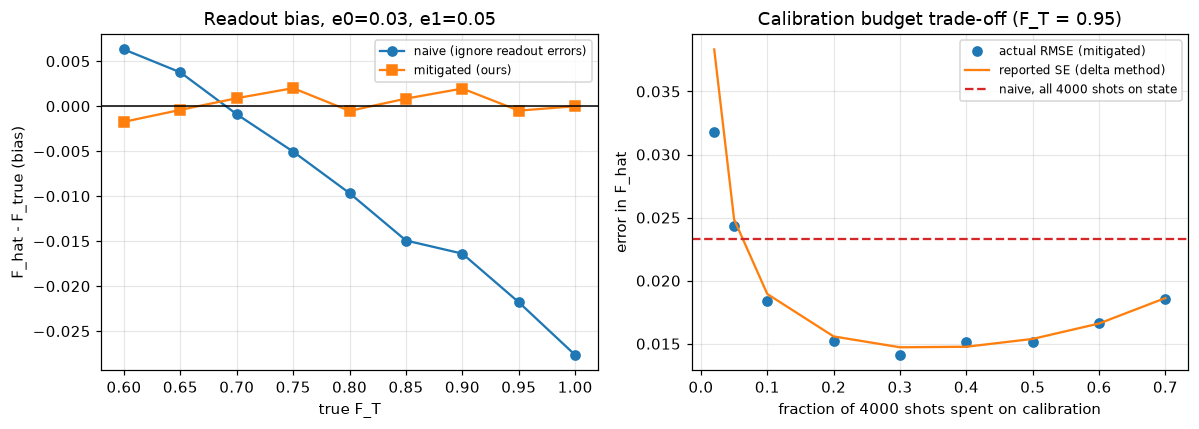

best calibration fraction in this scan: 0.30


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

F_grid = np.linspace(0.6, 1.0, 9)
naive = [estimate_fidelity(Lab(depolarized_T(F), READOUT, rng=rng), 400_000)[0] for F in F_grid]
mitig = [estimate_fidelity_mitigated(Lab(depolarized_T(F), READOUT, rng=rng), 400_000, 400_000)[0] for F in F_grid]
ax1.plot(F_grid, np.array(naive) - F_grid, "o-", label="naive (ignore readout errors)")
ax1.plot(F_grid, np.array(mitig) - F_grid, "s-", label="mitigated (ours)")
ax1.axhline(0, color="k", lw=1)
ax1.set(xlabel="true F_T", ylabel="F_hat - F_true (bias)", title=f"Readout bias, e0={READOUT[0]}, e1={READOUT[1]}")
ax1.legend(fontsize=8)

N_TOTAL, rho_test = 4000, depolarized_T(0.95)
fractions = np.array([0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7])
rmse, mean_se = [], []
for f in fractions:
    n_cal = int(round(f * N_TOTAL / 2)) * 2
    runs = np.array([estimate_fidelity_mitigated(Lab(rho_test, READOUT, rng=rng), N_TOTAL - n_cal, n_cal)[:2]
                     for _ in range(1500)])
    rmse.append(np.sqrt(np.mean((runs[:, 0] - 0.95) ** 2)))
    mean_se.append(np.sqrt(np.mean(runs[:, 1] ** 2)))
naive_rmse = np.sqrt(np.mean([(estimate_fidelity(Lab(rho_test, READOUT, rng=rng), N_TOTAL)[0] - 0.95) ** 2
                              for _ in range(1500)]))
ax2.plot(fractions, rmse, "o", label="actual RMSE (mitigated)")
ax2.plot(fractions, mean_se, "-", label="reported SE (delta method)")
ax2.axhline(naive_rmse, color="C3", ls="--", label="naive, all 4000 shots on state")
ax2.set(xlabel="fraction of 4000 shots spent on calibration", ylabel="error in F_hat",
        title="Calibration budget trade-off (F_T = 0.95)")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"best calibration fraction in this scan: {fractions[np.argmin(rmse)]:.2f}")

### Experiment 5: does propagating calibration uncertainty matter?

We fix 4,000 shots on the state and vary the number of calibration shots. For each setting we check the 95% interval's coverage under two error bars:
- the **full** SE, which includes calibration noise,
- a **naive** SE, which treats $\hat\eta$ and $\hat\beta$ as exact.

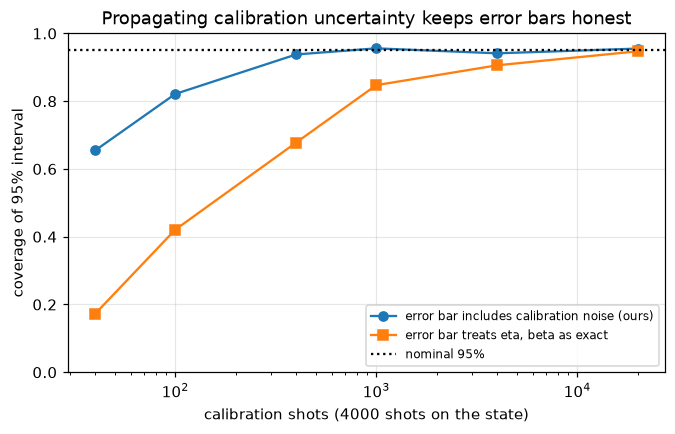

    40 calibration shots: coverage 65.5% (ours) vs 17.3% (ignoring calibration noise)
   100 calibration shots: coverage 82.1% (ours) vs 42.1% (ignoring calibration noise)
   400 calibration shots: coverage 93.8% (ours) vs 67.8% (ignoring calibration noise)
  1000 calibration shots: coverage 95.6% (ours) vs 84.7% (ignoring calibration noise)
  4000 calibration shots: coverage 94.1% (ours) vs 90.6% (ignoring calibration noise)
 20000 calibration shots: coverage 95.5% (ours) vs 94.7% (ignoring calibration noise)


In [10]:
cal_grid = [40, 100, 400, 1000, 4000, 20000]
rho_test = depolarized_T(0.95)
cov_full, cov_ignore = [], []
for nc in cal_grid:
    hit_full = hit_ign = 0
    for _ in range(1500):
        F, se_full, info = estimate_fidelity_mitigated(Lab(rho_test, READOUT, rng=rng), 4000, nc)
        hit_full += abs(F - 0.95) <= 1.96 * se_full
        hit_ign += abs(F - 0.95) <= 1.96 * info["se_ignoring_calibration"]
    cov_full.append(hit_full / 1500)
    cov_ignore.append(hit_ign / 1500)

plt.figure(figsize=(7, 4))
plt.semilogx(cal_grid, cov_full, "o-", label="error bar includes calibration noise (ours)")
plt.semilogx(cal_grid, cov_ignore, "s-", label="error bar treats eta, beta as exact")
plt.axhline(0.95, color="k", ls=":", label="nominal 95%")
plt.xlabel("calibration shots (4000 shots on the state)")
plt.ylabel("coverage of 95% interval")
plt.ylim(0, 1.0)
plt.title("Propagating calibration uncertainty keeps error bars honest")
plt.legend(fontsize=8)
plt.show()
for nc, cf, ci in zip(cal_grid, cov_full, cov_ignore):
    print(f"{nc:6d} calibration shots: coverage {cf:.1%} (ours) vs {ci:.1%} (ignoring calibration noise)")

### Level 3 takeaways
- **Ignoring readout errors gives a systematic bias** of about −0.02 to −0.03 near $F_T = 0.95$–$1$. A true $F_T = 0.97$ state looks like about 0.947, **below the threshold**. More shots don't help, because bias isn't noise: even with 400,000 shots the naive estimate stays off by about −0.022 at $F_T = 0.95$.
- **The bias depends on the state.** It is negative near $|T\rangle$ (where $\eta$ shrinks the vector) but positive at low fidelity (where the offset $\beta$ dominates), crossing zero around $F_T \approx 0.68$. So it can't be fixed by subtracting a constant; you need the full $(\eta,\beta)$ model.
- **Calibration removes the bias** at every fidelity. The remaining wiggles of about ±0.002 are statistical noise (the standard error at 400,000 shots is about 0.001).
- **Calibration has a price.** With a fixed budget, too little calibration leaves noisy $\hat\eta,\hat\beta$, and too much starves the state measurement. The error has a **broad minimum at about 20–50% of shots on calibration** (30% was best in this scan, but 20–50% are within noise of each other). At 5% calibrating is already slightly *worse* than not calibrating, and at 2% it is clearly worse. In practice one calibration is shared by many states, which makes it nearly free per state.
- **Calibration noise must be included in the error bar.** From 400 calibration shots up, the delta-method interval covers about 95%. The "treat $\hat\eta,\hat\beta$ as exact" interval covers only about 68% at 400 shots and 85% at 1,000. It catches up (about 91% at 4,000 and 95% at 20,000) only once calibration noise becomes small next to the noise from measuring the state.
- **Failure mode: very small calibration budgets.** With 40–100 calibration shots even our interval under-covers (about 66% and 82%), for two reasons. The correction divides by $\hat\eta$, which is too nonlinear for a first-order Taylor expansion when $\hat\eta$ is noisy. And with about 20 shots on $|0\rangle$ you often see no errors at all (probability $0.97^{20} \approx 54\%$), so the estimated variance of $\hat c_0$ is 0. **Rule:** use at least about 200 shots per reference state (400 in total), the smallest budget in this scan with coverage close to 95% (94%).
- **Failure mode (next cell): state-preparation errors look like readout errors.** Calibration assumes $|0\rangle$ and $|1\rangle$ are prepared perfectly. If they aren't, the method blames the detector and over-corrects, biasing $\hat F_T$ **upward**: with a 2% reference-prep error, a true $F_T = 0.95$ state reads about 0.967. That is the dangerous direction for certification. From these measurements alone, prep errors and readout errors cannot be told apart (the "SPAM" ambiguity).

In [11]:
# Failure mode: the |0>/|1> reference states are themselves prepared with a 2% error
print(" true F | mitigated, perfect references | mitigated, 2% reference prep error")
for F in [0.90, 0.95, 0.99]:
    good = estimate_fidelity_mitigated(Lab(depolarized_T(F), READOUT, rng=rng), 400_000, 400_000)[0]
    bad = estimate_fidelity_mitigated(Lab(depolarized_T(F), READOUT, reference_prep_error=0.02, rng=rng),
                                      400_000, 400_000)[0]
    print(f"  {F:.2f} |             {good:.4f}             |          {bad:.4f}  (bias {bad - F:+.4f})")

 true F | mitigated, perfect references | mitigated, 2% reference prep error
  0.90 |             0.8993             |          0.9178  (bias +0.0178)
  0.95 |             0.9532             |          0.9672  (bias +0.0172)
  0.99 |             0.9910             |          1.0000  (bias +0.0100)


---
# Level 4: Certify the state ($F_T \ge 0.95$?) with as few shots as possible

### Idea
We now need a **decision** (PASS, FAIL or INCONCLUSIVE) with a **guaranteed** small chance of being wrong, using as few shots as possible. The natural plan is to measure a few shots, check whether we're sure yet, and stop as soon as we are. That plan hides a statistical trap.

### The trap: optional stopping
A normal 95% confidence interval has a 5% error rate **if you look once**. If you check after every batch and stop the first time it looks good, you get many chances for a random fluctuation to fool you, and the error rate grows well beyond 5%. Experiment 7 shows this directly.

### Our protocol in two steps

**Step 1: reduce everything to one biased coin.** For each shot, flip a fair coin to choose $X$ or $Z$, measure, and record a 1 if the outcome is $+1$. The probability of recording a 1 is

$$p = \tfrac12\left(\tfrac{1 + r_x}{2}\right) + \tfrac12\left(\tfrac{1 + r_z}{2}\right) = \tfrac12 + \tfrac{r_x + r_z}{4} = \tfrac12 + \frac{F_T - \tfrac12}{\sqrt2}.$$

So **every shot is an independent coin flip whose bias is a fixed, increasing function of $F_T$**, and "$F_T \ge 0.95$" becomes exactly "$p \ge p^* = 0.8182$". The randomized basis choice is what makes the shots identically distributed. That makes the statistics exact rather than approximate.

**Step 2: an anytime-valid confidence sequence for the coin.** For any candidate bias $p_0$, define the "evidence", a mixture likelihood ratio in the style of Robbins [7]

$$M_n(p_0) = \frac{\int_0^1 q^{S}(1-q)^{n-S}\,\pi(q)\,dq}{p_0^{S}(1-p_0)^{n-S}} \qquad (S = \text{number of 1s in } n \text{ shots}),$$

the likelihood of the data averaged over a prior $\pi$ (a Beta distribution), divided by its likelihood if $p = p_0$.

- **Betting interpretation** [9]: $M_n(p_0)$ is the wealth of a gambler who starts with \$1 and keeps betting against "$p = p_0$" at fair odds. If $p_0$ is the truth, the bets are fair and the wealth is a **martingale**.
- **Ville's inequality** [6]: a fair game's wealth reaches $1/\alpha$ **at any time, ever** with probability at most $\alpha$.
- So the set $C_n = \{p_0 : M_n(p_0) < 1/\alpha\}$ contains the true $p$ **at all times simultaneously** with probability $\ge 1-\alpha$. It is a *confidence sequence* [8]: an interval you may check after every shot and stop whenever you like.

**Decision rule.** After each batch of shots:
- **PASS** if the whole interval $C_n$ lies above $p^*$ (equivalently, the interval on $F_T$ lies above 0.95).
- **FAIL** if the whole interval lies below $p^*$.
- **INCONCLUSIVE** if the shot budget runs out first.

**Guarantee.** A wrong decision means PASSing a state with $F_T < 0.95$, or FAILing one with $F_T \ge 0.95$. Either requires the true $p$ to leave the confidence sequence at some point. So $P(\text{wrong decision}) \le \alpha$ (we use $\alpha = 0.05$), **regardless of when we stop**. We also report the interval on $F_T$ at the stopping time, which carries the same guarantee.

**Prior choice.** We use a Beta prior centered on $p^*$ with concentration $\kappa = 200$. The prior affects **only efficiency, never validity**, because Ville's inequality [6] holds for any fixed prior (Experiment 10 compares several).

In [12]:
def p_from_F(F, eta=1.0, beta=0.0):
    # P(one random-Pauli shot reports +1) for a state with fidelity F (optionally through readout (eta, beta))
    return 0.5 + beta / 2 + eta * (F - 0.5) / SQ2


def F_from_p(p, eta=1.0, beta=0.0):
    return 0.5 + (2 * p - 1 - beta) / (eta * SQ2)


def log_evidence(S, n, p0, a, b):
    # log M_n(p0): Beta(a,b)-mixture likelihood ratio against p = p0 (a test martingale when p0 is true)
    return betaln(a + S, b + n - S) - betaln(a, b) - S * np.log(p0) - (n - S) * np.log1p(-p0)


P_GRID = np.linspace(1e-6, 1 - 1e-6, 40001)


def confidence_sequence(S, n, alpha, a, b):
    # anytime-valid (1 - alpha) interval for the coin bias p after n shots with S ones
    inside = P_GRID[log_evidence(S, n, P_GRID, a, b) < np.log(1 / alpha)]
    return inside.min(), inside.max()


def random_pauli_shots(lab, k, rng):
    # k shots, each in X or Z chosen by a fair coin; returns 1 for outcome +1, else 0
    use_x = rng.random(k) < 0.5
    out = np.empty(k, dtype=int)
    out[use_x] = lab.measure("X", int(use_x.sum()))
    out[~use_x] = lab.measure("Z", int((~use_x).sum()))
    return (out == 1).astype(int)


def certify(lab, F_threshold=0.95, alpha=0.05, max_shots=30_000, batch=50, prior_strength=200,
            readout_cal=None, measurement="pauli", rng=None):
    # Level 4: sequential test of F_T >= F_threshold. Returns a dict with decision, shots, F interval, evidence.
    # readout_cal: None (perfect readout) or the output of calibrate_for_certification() (Level 4b)
    rng = rng if rng is not None else np.random.default_rng()
    shots_before = lab.shots_used
    if measurement == "T-basis":                      # non-Pauli benchmark: the coin bias IS F_T
        p_pass = p_fail = F_threshold
        to_F_lo = to_F_hi = lambda p: p
    elif readout_cal is None:                        # perfect readout
        p_pass = p_fail = p_from_F(F_threshold)
        to_F_lo = to_F_hi = lambda p: F_from_p(p)
    else:                                            # noisy readout, conservative thresholds from calibration
        p_pass, p_fail = readout_cal["p_pass"], readout_cal["p_fail"]
        corners = readout_cal["corners"]
        to_F_lo = lambda p: min(F_from_p(p, *c) for c in corners)
        to_F_hi = lambda p: max(F_from_p(p, *c) for c in corners)

    center = (p_pass + p_fail) / 2
    a, b = prior_strength * center, prior_strength * (1 - center)
    log_thr = np.log(1 / alpha)
    S = n = 0
    decision = "INCONCLUSIVE"
    while n < max_shots:
        k = min(batch, max_shots - n)
        bits = (lab.measure_T_basis(k) == 1) if measurement == "T-basis" else random_pauli_shots(lab, k, rng)
        S += int(bits.sum())
        n += k
        # interval entirely above p_pass  <=>  p_hat > p_pass and p_pass is excluded
        if S / n > p_pass and log_evidence(S, n, p_pass, a, b) >= log_thr:
            decision = "PASS"
            break
        if S / n < p_fail and log_evidence(S, n, p_fail, a, b) >= log_thr:
            decision = "FAIL"
            break
    pL, pU = confidence_sequence(S, n, alpha, a, b)
    return {"decision": decision,
            "shots": lab.shots_used - shots_before,
            "F_hat": float(np.clip(to_F_lo(S / n) if readout_cal is None else F_from_p(S / n, readout_cal["eta"], readout_cal["beta"]), 0, 1)),
            "F_interval": (float(np.clip(to_F_lo(pL), 0, 1)), float(np.clip(to_F_hi(pU), 0, 1))),
            "evidence_vs_threshold": float(np.exp(max(log_evidence(S, n, p_pass, a, b), log_evidence(S, n, p_fail, a, b))))}


print(f"threshold on the coin: p* = p(F=0.95) = {p_from_F(0.95):.4f}   (a perfect |T> gives p = {p_from_F(1.0):.4f})\n")
for F in [0.99, 0.95, 0.90]:
    res = certify(Lab(depolarized_T(F), rng=rng), rng=rng)
    lo, hi = res["F_interval"]
    print(f"true F = {F:.2f} -> {res['decision']:12s} after {res['shots']:6d} shots | F_hat = {res['F_hat']:.4f}, "
          f"95% anytime-valid interval [{lo:.4f}, {hi:.4f}] | evidence {res['evidence_vs_threshold']:.1f} (need 20)")

threshold on the coin: p* = p(F=0.95) = 0.8182   (a perfect |T> gives p = 0.8536)

true F = 0.99 -> PASS         after   1100 shots | F_hat = 1.0000, 95% anytime-valid interval [0.9514, 1.0000] | evidence 25.7 (need 20)
true F = 0.95 -> INCONCLUSIVE after  30000 shots | F_hat = 0.9498, 95% anytime-valid interval [0.9392, 0.9601] | evidence 0.1 (need 20)
true F = 0.90 -> FAIL         after   2150 shots | F_hat = 0.9118, 95% anytime-valid interval [0.8726, 0.9485] | evidence 29.7 (need 20)


### Experiment 7: why "peeking" at an ordinary confidence interval is dangerous

We simulate a state **exactly at** the threshold ($F_T = 0.95$). It should never PASS, so any PASS is a false certification.
We check after every 50 shots, up to 20,000 shots, using two rules:
- **naive:** PASS as soon as the usual one-sided 95% normal interval lies above 0.95;
- **ours:** PASS as soon as the confidence sequence lies above 0.95.

The plot shows the cumulative false-PASS rate as you keep checking.

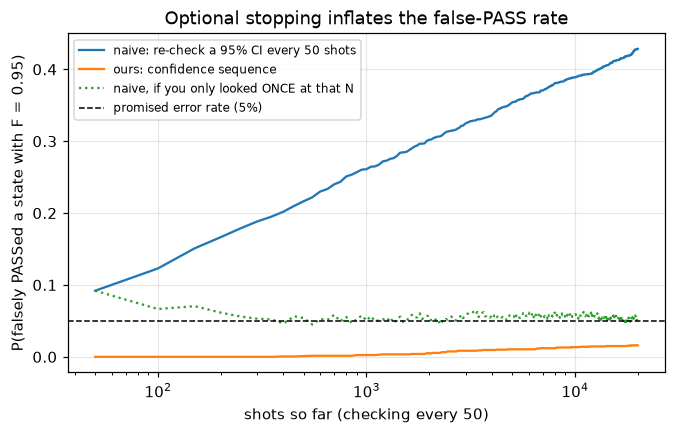

after 20,000 shots: naive peeking false-PASS rate = 42.9%, ours = 1.6%


In [13]:
TRIALS, NMAX, BATCH, ALPHA = 2000, 20_000, 50, 0.05
p_star = p_from_F(0.95)
a0, b0 = 200 * p_star, 200 * (1 - p_star)
checks = np.arange(BATCH, NMAX + 1, BATCH)

bits = np.array([random_pauli_shots(Lab(depolarized_T(0.95), rng=rng), NMAX, rng) for _ in range(TRIALS)])
S = np.cumsum(bits, axis=1)[:, checks - 1]
p_hat = S / checks

naive_pass = p_hat - stats.norm.ppf(1 - ALPHA) * np.sqrt(p_hat * (1 - p_hat) / checks) > p_star
ours_pass = (p_hat > p_star) & (log_evidence(S, checks, p_star, a0, b0) >= np.log(1 / ALPHA))

plt.figure(figsize=(7, 4))
plt.semilogx(checks, np.maximum.accumulate(naive_pass, axis=1).mean(axis=0), label="naive: re-check a 95% CI every 50 shots")
plt.semilogx(checks, np.maximum.accumulate(ours_pass, axis=1).mean(axis=0), label="ours: confidence sequence")
plt.semilogx(checks, naive_pass.mean(axis=0), ":", label="naive, if you only looked ONCE at that N")
plt.axhline(ALPHA, color="k", ls="--", lw=1, label="promised error rate (5%)")
plt.xlabel("shots so far (checking every 50)")
plt.ylabel("P(falsely PASSed a state with F = 0.95)")
plt.title("Optional stopping inflates the false-PASS rate")
plt.legend(fontsize=8)
plt.show()
print(f"after 20,000 shots: naive peeking false-PASS rate = {np.maximum.accumulate(naive_pass, axis=1)[:, -1].mean():.1%}, "
      f"ours = {np.maximum.accumulate(ours_pass, axis=1)[:, -1].mean():.1%}")

### Experiment 8: decisions and shot usage across states above, near and below the threshold

For each state we run 200 independent certifications ($\alpha = 0.05$, budget 30,000 shots, checking every 50).
States are depolarized $|T\rangle$ at many fidelities, plus **two pure, coherently tilted states** ($F_T = 0.97$ and $0.93$). Those check that the protocol cares only about $F_T$, not the type of error.

state              PASS   FAIL  INCONC  WRONG  median shots  90th pct


depol F=0.99     100.0%   0.0%    0.0%   0.0%          1500      2755


depol F=0.98     100.0%   0.0%    0.0%   0.0%          2300      4920


depol F=0.97     100.0%   0.0%    0.0%   0.0%          5475     12115


depol F=0.96      51.5%   0.0%   48.5%   0.0%         29325     30000


depol F=0.955      9.5%   0.5%   90.0%   0.5%         30000     30000


... (4 outputs left out)

depol F=0.92       0.0% 100.0%    0.0%   0.0%          2550      5555
depol F=0.9        0.0% 100.0%    0.0%   0.0%          1050      2010


depol F=0.85       0.0% 100.0%    0.0%   0.0%           350       600


tilted F=0.97    100.0%   0.0%    0.0%   0.0%          6000     12865


tilted F=0.93      0.0% 100.0%    0.0%   0.0%          6050     13320


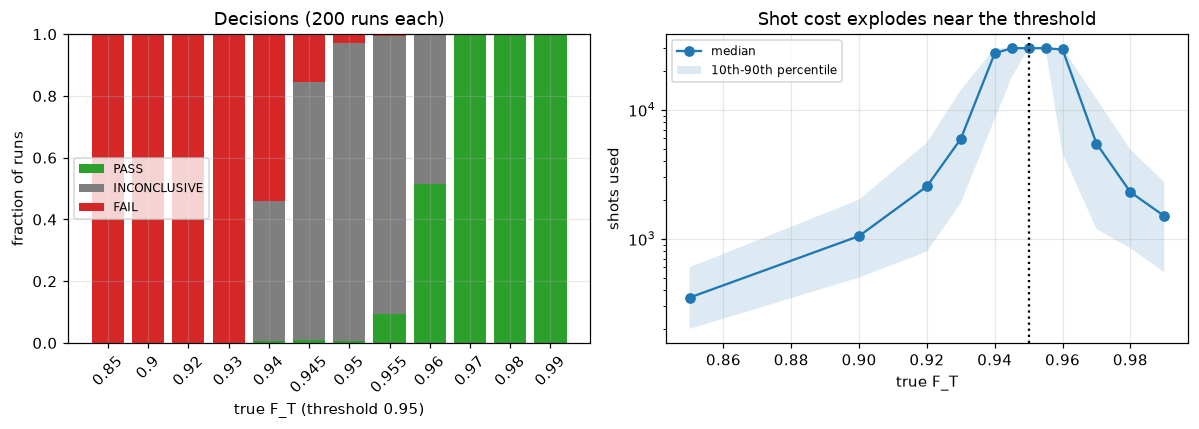

In [14]:
L4_STATES = [(f"depol F={F}", F, depolarized_T(F)) for F in [0.99, 0.98, 0.97, 0.96, 0.955, 0.95, 0.945, 0.94, 0.93, 0.92, 0.90, 0.85]]
L4_STATES += [("tilted F=0.97", 0.97, tilted_T(0.97)), ("tilted F=0.93", 0.93, tilted_T(0.93))]
TRIALS = 200

table = []
print(f"{'state':16s} {'PASS':>6s} {'FAIL':>6s} {'INCONC':>7s} {'WRONG':>6s} {'median shots':>13s} {'90th pct':>9s}")
for name, F, rho in L4_STATES:
    runs = [certify(Lab(rho, rng=rng), rng=rng) for _ in range(TRIALS)]
    dec = np.array([r["decision"] for r in runs])
    shots = np.array([r["shots"] for r in runs])
    wrong = np.mean(dec == "FAIL") if F >= 0.95 else np.mean(dec == "PASS")   # F >= 0.95 meets the spec
    row = dict(name=name, F=F, PASS=np.mean(dec == "PASS"), FAIL=np.mean(dec == "FAIL"),
               INC=np.mean(dec == "INCONCLUSIVE"), wrong=wrong, med=np.median(shots),
               p10=np.percentile(shots, 10), p90=np.percentile(shots, 90))
    table.append(row)
    print(f"{name:16s} {row['PASS']:6.1%} {row['FAIL']:6.1%} {row['INC']:7.1%} {row['wrong']:6.1%} "
          f"{row['med']:13.0f} {row['p90']:9.0f}")

depol = sorted([r for r in table if r["name"].startswith("depol")], key=lambda r: r["F"])
Fs = np.array([r["F"] for r in depol])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(depol))
ax1.bar(x, [r["PASS"] for r in depol], color="C2", label="PASS")
ax1.bar(x, [r["INC"] for r in depol], bottom=[r["PASS"] for r in depol], color="C7", label="INCONCLUSIVE")
ax1.bar(x, [r["FAIL"] for r in depol], bottom=[r["PASS"] + r["INC"] for r in depol], color="C3", label="FAIL")
ax1.set_xticks(x, [f"{F:g}" for F in Fs], rotation=45)
ax1.set(xlabel="true F_T (threshold 0.95)", ylabel="fraction of runs", title="Decisions (200 runs each)")
ax1.legend(fontsize=8, loc="center left")
ax2.semilogy(Fs, [r["med"] for r in depol], "o-", label="median")
ax2.fill_between(Fs, [r["p10"] for r in depol], [r["p90"] for r in depol], alpha=0.15, label="10th-90th percentile")
ax2.axvline(0.95, color="k", ls=":")
ax2.set(xlabel="true F_T", ylabel="shots used", title="Shot cost explodes near the threshold")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Experiment 9: what would a non-Pauli measurement buy?

We run the same certification procedure, but each shot is a $T$-basis measurement, a coin with bias exactly $F_T$.
This is **not allowed** by the challenge's Pauli-only rule. It shows **why** the Pauli version is expensive: each Pauli shot is intrinsically noisy.

In [15]:
print(f"{'true F':>7s} {'Pauli median shots':>19s} {'T-basis median shots':>21s} {'ratio':>6s}")
for F in [0.99, 0.98, 0.97, 0.93, 0.90]:
    pauli = np.median([certify(Lab(depolarized_T(F), rng=rng), rng=rng)["shots"] for _ in range(100)])
    tb = np.median([certify(Lab(depolarized_T(F), rng=rng), measurement="T-basis", batch=10, rng=rng)["shots"]
                    for _ in range(100)])
    print(f"{F:7.2f} {pauli:19.0f} {tb:21.0f} {pauli / tb:6.1f}x")

 true F  Pauli median shots  T-basis median shots  ratio


   0.99                1500                   260    5.8x


   0.98                2225                   400    5.6x


   0.97                4825                   825    5.8x


   0.93                4750                   980    4.8x
   0.90                1050                   260    4.0x


### Experiment 10: the prior changes efficiency, not correctness

We try several prior concentrations $\kappa$, from nearly flat ($\kappa = 2$) to very peaked ($\kappa = 2000$). All of them keep the error guarantee. They differ only in how many shots they need.

In [16]:
print(f"{'kappa':>6s}" + "".join(f"  F={F}: med shots / wrong" for F in [0.99, 0.97, 0.92]))
for kappa in [2, 20, 200, 2000]:
    line = f"{kappa:6d}"
    for F in [0.99, 0.97, 0.92]:
        runs = [certify(Lab(depolarized_T(F), rng=rng), prior_strength=kappa, rng=rng) for _ in range(80)]
        wrong = np.mean([r["decision"] == ("FAIL" if F > 0.95 else "PASS") for r in runs])
        line += f"  {np.median([r['shots'] for r in runs]):>13.0f} / {wrong:4.0%}  "
    print(line)

 kappa  F=0.99: med shots / wrong  F=0.97: med shots / wrong  F=0.92: med shots / wrong


     2           2200 /   0%             7675 /   0%             5000 /   0%  


    20           1400 /   0%             8025 /   0%             2600 /   0%  


   200           1325 /   0%             6350 /   0%             2800 /   0%  


  2000           2050 /   0%             6200 /   0%             3225 /   0%  


### Level 4b: certification with a noisy detector

Combining Levels 3 and 4: the detector has readout errors $(e_0, e_1) = (3\%, 5\%)$. The coin's bias becomes

$$p_\text{obs} = \tfrac12 + \tfrac{\beta}{2} + \frac{\eta\,(F_T - \tfrac12)}{\sqrt2},$$

so the threshold on the coin depends on the unknown $\eta$ and $\beta$. Plugging in point estimates would quietly lose the guarantee. Instead we stay **conservative**:

1. **Calibrate** with $n_c$ shots each on $|0\rangle$ and $|1\rangle$. Exact (Clopper–Pearson [5]) one-sided bounds give a box that contains the true $(c_0, c_1)$ with probability $\ge 1 - \alpha_\text{cal}$.
2. **To PASS**, the coin must beat the **highest** threshold consistent with the box. **To FAIL**, it must fall below the **lowest** one. Between the two thresholds is a small "dead zone" caused by calibration uncertainty. It shrinks as $n_c$ grows.
3. **Error budget:** $P(\text{wrong}) \le \alpha_\text{cal} + \alpha_\text{test} = 0.01 + 0.04 = 0.05$ (union bound).

Calibration shots are **counted** in the reported totals.

In [17]:
def calibrate_for_certification(lab, shots_per_reference, F_threshold=0.95, alpha_cal=0.01):
    # Level 4b: exact one-sided bounds on the readout, turned into conservative PASS / FAIL coin thresholds
    n = shots_per_reference
    k0 = int((lab.measure_reference("0", n) == 1).sum())   # P(+1 | |0>) = (1 + c0)/2
    k1 = int((lab.measure_reference("1", n) == 1).sum())   # P(+1 | |1>) = (1 + c1)/2
    a = alpha_cal / 2                                      # union bound over the two references (per direction)
    upper = lambda k: 1.0 if k == n else stats.beta.ppf(1 - a, k + 1, n - k)   # Clopper-Pearson
    lower = lambda k: 0.0 if k == 0 else stats.beta.ppf(a, k, n - k + 1)
    c0_lo, c0_hi = 2 * lower(k0) - 1, 2 * upper(k0) - 1
    c1_lo, c1_hi = 2 * lower(k1) - 1, 2 * upper(k1) - 1
    kk = SQ2 * (F_threshold - 0.5)                         # beta + eta*kk = c0(1+kk)/2 + c1(1-kk)/2, increasing in both
    worst_high = (c0_hi * (1 + kk) + c1_hi * (1 - kk)) / 2
    worst_low = (c0_lo * (1 + kk) + c1_lo * (1 - kk)) / 2
    c0, c1 = 2 * k0 / n - 1, 2 * k1 / n - 1
    corners = [((x0 - x1) / 2, (x0 + x1) / 2) for x0 in (c0_lo, c0_hi) for x1 in (c1_lo, c1_hi)]   # (eta, beta)
    return {"p_pass": 0.5 + worst_high / 2, "p_fail": 0.5 + worst_low / 2, "corners": corners,
            "eta": (c0 - c1) / 2, "beta": (c0 + c1) / 2}


print("Dead zone (in F) caused by calibration uncertainty, for different calibration budgets:")
for n_ref in [1000, 5000, 20000]:
    cal = calibrate_for_certification(Lab(depolarized_T(1.0), READOUT, rng=rng), n_ref)
    Fp = F_from_p(cal["p_pass"], cal["eta"], cal["beta"])
    Ff = F_from_p(cal["p_fail"], cal["eta"], cal["beta"])
    print(f"  {2 * n_ref:6d} calibration shots: must look like F > {Fp:.4f} to PASS, F < {Ff:.4f} to FAIL")

N_REF = 10_000
print(f"\nCertification with readout errors {READOUT}, {2 * N_REF} calibration shots (counted), 100 runs each:")
print(f"{'true F':>7s} | {'ours (calibrated)':^34s} | {'ignoring readout errors':^28s}")
print(f"{'':7s} | {'PASS':>6s} {'FAIL':>6s} {'INC':>6s} {'med shots':>10s} | {'PASS':>6s} {'FAIL':>6s} {'INC':>6s}")
print("(med shots includes the calibration shots; F >= 0.95 should never FAIL, F < 0.95 should never PASS)")
for F in [0.99, 0.98, 0.97, 0.96, 0.95, 0.93, 0.90]:
    ours, naive = [], []
    for _ in range(100):
        lab = Lab(depolarized_T(F), READOUT, rng=rng)
        cal = calibrate_for_certification(lab, N_REF)
        ours.append(certify(lab, alpha=0.04, readout_cal=cal, rng=rng))
        naive.append(certify(Lab(depolarized_T(F), READOUT, rng=rng), rng=rng))
    d1 = np.array([r["decision"] for r in ours])
    d2 = np.array([r["decision"] for r in naive])
    print(f"{F:7.2f} | {np.mean(d1 == 'PASS'):6.0%} {np.mean(d1 == 'FAIL'):6.0%} {np.mean(d1 == 'INCONCLUSIVE'):6.0%} "
          f"{np.median([r['shots'] for r in ours]) + 2 * N_REF:10.0f} | "
          f"{np.mean(d2 == 'PASS'):6.0%} {np.mean(d2 == 'FAIL'):6.0%} {np.mean(d2 == 'INCONCLUSIVE'):6.0%}")

Dead zone (in F) caused by calibration uncertainty, for different calibration budgets:
    2000 calibration shots: must look like F > 0.9698 to PASS, F < 0.9253 to FAIL
   10000 calibration shots: must look like F > 0.9598 to PASS, F < 0.9393 to FAIL
   40000 calibration shots: must look like F > 0.9550 to PASS, F < 0.9448 to FAIL

Certification with readout errors (0.03, 0.05), 20000 calibration shots (counted), 100 runs each:
 true F |         ours (calibrated)          |   ignoring readout errors   
        |   PASS   FAIL    INC  med shots |   PASS   FAIL    INC
(med shots includes the calibration shots; F >= 0.95 should never FAIL, F < 0.95 should never PASS)


   0.99 |   100%     0%     0%      22725 |    96%     0%     4%


   0.98 |   100%     0%     0%      25625 |    20%     1%    79%


   0.97 |    71%     0%    29%      40225 |     0%    10%    90%


   0.96 |     6%     0%    94%      50000 |     0%    81%    19%


   0.95 |     0%     0%   100%      50000 |     0%   100%     0%


   0.93 |     0%    63%    37%      41250 |     0%   100%     0%


   0.90 |     0%   100%     0%      21950 |     0%   100%     0%


### Level 4 takeaways
- **Correctness under optional stopping.** Re-checking an ordinary 95% interval after every batch falsely certifies a borderline state far more often than 5%. The confidence sequence stays below 5% no matter how often we check, because its guarantee holds **at all times simultaneously** (Ville's inequality [6]; confidence sequences [8]).
- **Few wrong decisions in practice.** Across all tested states, the wrong-decision rate never exceeds a few percent, always under the 5% bound. The worst case is a state sitting exactly on the threshold, as theory predicts.
- **Cost depends on distance from the threshold.** Roughly, shots $\propto 1/(F_T - 0.95)^2$. Clear cases ($F_T = 0.99$ or $\le 0.92$) are decided in a few thousand shots or fewer. States within about 0.01 of the threshold often end **INCONCLUSIVE**. That is the correct, honest answer: telling 0.955 from 0.95 at 95% confidence genuinely needs more than 30,000 Pauli shots.
- **A PASS is never cheap.** At equal distance from the threshold, PASS and FAIL cost about the same (0.97 and 0.93 both take about 6,000 shots). But even a perfect $|T\rangle$ is only 0.05 above the threshold ($\Delta p = 0.035$ on the coin), so passing typically costs 1,000+ shots (median 1,500 at $F_T = 0.99$). Clearly bad states can be far below and fail in a few hundred.
- **Error type doesn't matter.** Coherent (tilted) and incoherent (depolarized) errors with the same $F_T$ behave the same, because the test only sees $F_T$.
- **Pauli measurements are the bottleneck.** A $T$-basis measurement would certify several times faster, but it isn't allowed (it requires a non-Clifford rotation).
- **With noisy readout,** ignoring errors produces **wrong FAILs** of states that meet the spec (100% at $F_T = 0.95$, 81% at 0.96, even 10% at 0.97), and good states rarely PASS (20% at 0.98). Conservative calibration restores correctness. It costs extra calibration shots (20,000 here, shareable across many states) and a dead zone around the threshold where the answer is INCONCLUSIVE.

---
# Bonus: running the protocol on a real quantum computer (IQM Resonance)

Everything above uses simulated measurements, as the challenge asks. That is what lets us **grade** the methods, because we know the true state. This bonus section asks a different question: **do the same estimators, unchanged, work on data from a real superconducting qubit?** We use IQM's cloud service Resonance [10] and the `iqm-client` Qiskit integration [11].

### What changes on hardware
- **The readout errors are real.** Level 3 assumed $(e_0, e_1) = (3\%, 5\%)$. Here they are whatever the chip does, and Level 3's calibration has to discover them.
- **There is no ground truth.** We prepare $|T\rangle$ with a single rotation $R_y(\pi/4)$, but the chip adds its own gate errors and decoherence. So we can't score the estimates the way we did above. Instead we check that they are **self-consistent**: the raw and readout-corrected estimates should differ in the way Level 3 predicts, and the certification decisions should agree with the corrected intervals.
- **"Nominal F"** below means the fidelity a perfect device would produce. Tilted states are prepared as $R_y(\pi/4 + \delta)$, with $F_\text{nominal} = \cos^2(\delta/2)$. The real fidelity is lower by however much the device itself degrades the state.

### Design: one job, then replay
Level 4 checks after every 50 shots. Sending one cloud job per batch would mean hundreds of jobs and long queue waits. Instead:

1. **One job** of 11 circuits collects `HW_SHOTS` single-shot outcomes, in time order, for each of:
   - $X$, $Y$ and $Z$ on three states: $|T\rangle$, and tilted states with nominal $F = 0.97$ and $0.90$;
   - the reference states $|0\rangle$ and $|1\rangle$.
2. A `HardwareLab` object offers the **same interface as `Lab`**. Each call hands out the next **unused** recorded shots of the requested basis. So `reconstruct_state`, `estimate_fidelity`, `estimate_fidelity_mitigated`, `calibrate_for_certification` and `certify` run **unchanged**.

Because shots are independent, handing out recorded shots in order is statistically the same as measuring on demand. Level 4's random X/Z choice is still made per shot. Each level starts from a fresh `HardwareLab`, so **levels reuse the same recorded data** (each is a separate analysis of one dataset). Within a level no shot is used twice, and the reported shot counts are exact. All three states share one set of calibration shots, as they would in a real lab.

### How to run (three modes)
- **Saved data (default if the file exists):** loads `hardware_data/magic_state_hardware.json`. This is free, and it makes the section reproducible for anyone without a Resonance account.
- **Dry run (default otherwise):** collects the same data from IQM's **Garnet noise model** on your laptop. Free, no token needed.
- **Real hardware:** set `RUN_ON_HARDWARE = True` with `IQM_TOKEN`, `IQM_SERVER_URL` and `IQM_QUANTUM_COMPUTER` in a `.env` file next to the notebook (copy `.env.example`; see `README.md`). This **uses Resonance credits** (11 circuits × `HW_SHOTS` shots), and the results are saved to the file above, so you only pay once. Delete the file to collect new data.

In [18]:
import json
import os
import pathlib
from datetime import datetime, timezone
from qiskit import QuantumCircuit

# ---------------- configuration ----------------
HW_SHOTS = 10_000          # shots per circuit; 11 circuits -> 110,000 shots in total
HW_QUBIT = 0               # physical qubit; pick one with good readout fidelity on the Resonance calibration page
RUN_ON_HARDWARE = False   # True = submit to IQM Resonance (uses credits). Only needed once: results are saved.
HW_DATA_FILE = pathlib.Path("hardware_data/magic_state_hardware.json")

# name -> extra tilt delta (rad): the state is R_y(pi/4 + delta)|0>, nominal F = cos^2(delta/2)
HW_STATES = {"T": 0.0,
             "tilted, nominal F=0.97": 2 * np.arccos(np.sqrt(0.97)),
             "tilted, nominal F=0.90": 2 * np.arccos(np.sqrt(0.90))}


def state_circuit(delta, basis):
    # prepare the state, rotate so that a Z readout measures `basis`, read out
    qc = QuantumCircuit(1)
    qc.ry(np.pi / 4 + delta, 0)
    if basis == "X":
        qc.h(0)                    # H maps the X eigenstates |+>,|-> to |0>,|1>
    elif basis == "Y":
        qc.sdg(0)                  # S^dagger then H maps |+i>,|-i> to |0>,|1>
        qc.h(0)
    qc.measure_all()
    return qc


def reference_circuit(label):
    # calibration reference: |0> (do nothing) or |1> (one X gate)
    qc = QuantumCircuit(1)
    if label == "1":
        qc.x(0)
    qc.measure_all()
    return qc


def collect_data(backend, shots, qubit, states, seed=None):
    # ONE job with every circuit; returns per-shot outcomes ('0'/'1' strings, in time order) plus metadata
    from iqm.qiskit_iqm import transpile_to_IQM
    keys, circuits = [], []
    for name, delta in states.items():
        for b in "XYZ":
            keys.append((name, b))
            circuits.append(state_circuit(delta, b))
    for label in "01":
        keys.append(("reference", label))
        circuits.append(reference_circuit(label))
    compiled = [transpile_to_IQM(c, backend, initial_layout=[qubit]) for c in circuits]   # pin one physical qubit

    if hasattr(backend, "noise_model"):
        # IQM fake backend: call its Aer noise simulation directly, because fake.run() drops memory=True
        from qiskit_aer import AerSimulator
        job = AerSimulator(noise_model=backend.noise_model).run(compiled, shots=shots, memory=True,
                                                                seed_simulator=seed)
        job_id = None
    else:
        job = backend.run(compiled, shots=shots)     # real hardware always returns per-shot memory
        job_id = job.job_id()
        print(f"submitted job {job_id}; waiting in the queue ...")
    result = job.result()

    outcomes = {}
    for i, (name, b) in enumerate(keys):
        bits = "".join(m.replace(" ", "")[-1] for m in result.get_memory(i))
        assert len(bits) == shots
        outcomes.setdefault(name, {})[b] = bits
    return {"backend": backend.name, "qubit": qubit, "shots": shots, "job_id": job_id,
            "calibration_set_id": str(getattr(backend, "_calibration_set_id", None)),
            "collected_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "states": {name: float(delta) for name, delta in states.items()},
            "outcomes": outcomes}


if HW_DATA_FILE.exists():
    hw_data = json.loads(HW_DATA_FILE.read_text())
    hw_source = f"saved data from {hw_data['backend']} (job {hw_data['job_id']}, collected {hw_data['collected_utc']})"
elif RUN_ON_HARDWARE:
    from dotenv import load_dotenv
    from iqm.qiskit_iqm import IQMProvider
    load_dotenv()
    provider = IQMProvider(os.environ.get("IQM_SERVER_URL", "https://resonance.iqm.tech/"),
                           quantum_computer=os.environ.get("IQM_QUANTUM_COMPUTER", "emerald"))
    hw_data = collect_data(provider.get_backend(), HW_SHOTS, HW_QUBIT, HW_STATES)
    HW_DATA_FILE.parent.mkdir(exist_ok=True)
    HW_DATA_FILE.write_text(json.dumps(hw_data))
    hw_source = f"real hardware: {hw_data['backend']} (job {hw_data['job_id']}), saved to {HW_DATA_FILE}"
else:
    from iqm.qiskit_iqm.fake_backends.fake_garnet import IQMFakeGarnet
    hw_data = collect_data(IQMFakeGarnet(), HW_SHOTS, HW_QUBIT, HW_STATES, seed=2026)
    hw_source = "DRY RUN on IQM's Garnet noise model (local simulator, no credits used)"

n_circ = 3 * len(hw_data["states"]) + 2
print("data source:", hw_source)
print(f"physical qubit {hw_data['qubit']} | {n_circ} circuits x {hw_data['shots']:,} shots = {n_circ * hw_data['shots']:,} shots")

data source: saved data from emerald (job 01a201b6-34b1-7255-b07e-e9d1dabd7814, collected 2026-11-22T05:33:49+00:00)
physical qubit 0 | 11 circuits x 10,000 shots = 110,000 shots


In [19]:
class HardwareLab:
    # Same public interface as Lab, but every outcome is a recorded single-shot result from the job above.
    # Each call hands out the NEXT unused shots of that basis, so no shot is used twice within one analysis.
    # The estimators can't tell it apart from the simulated Lab: they only ever see +1/-1 outcomes.

    def __init__(self, data, state):
        pm1 = lambda bits: np.where(np.frombuffer(bits.encode(), dtype=np.uint8) == ord("0"), 1, -1)   # '0' -> +1
        self._pools = {b: pm1(data["outcomes"][state][b]) for b in "XYZ"}
        self._pools.update({"ref" + label: pm1(data["outcomes"]["reference"][label]) for label in "01"})
        self._next = dict.fromkeys(self._pools, 0)
        self.shots_used = 0

    def _take(self, key, shots):
        start = self._next[key]
        if start + shots > len(self._pools[key]):
            raise RuntimeError(f"only {len(self._pools[key]) - start} unused '{key}' shots left; increase HW_SHOTS")
        self._next[key] = start + shots
        self.shots_used += shots
        return self._pools[key][start:start + shots]

    def measure(self, basis, shots):
        return self._take(basis, shots)

    def measure_reference(self, label, shots):
        return self._take("ref" + label, shots)

    def measure_T_basis(self, shots):
        raise NotImplementedError("the T-basis is not a Pauli measurement, so it is not run on hardware")


# The device's readout errors, measured from ALL reference shots (these include |0>/|1> preparation errors: SPAM)
ref0 = HardwareLab(hw_data, "T").measure_reference("0", hw_data["shots"])
ref1 = HardwareLab(hw_data, "T").measure_reference("1", hw_data["shots"])
hw_e0, hw_e1 = np.mean(ref0 == -1), np.mean(ref1 == 1)
hw_eta, hw_beta = 1 - hw_e0 - hw_e1, hw_e1 - hw_e0
print(f"measured readout errors: e0 = P(read 1 | prepared 0) = {hw_e0:.2%}, e1 = P(read 0 | prepared 1) = {hw_e1:.2%}")
print(f"  -> eta = {hw_eta:.4f}, beta = {hw_beta:+.4f}   (Level 3 assumed e0 = 3%, e1 = 5%)")

measured readout errors: e0 = P(read 1 | prepared 0) = 0.32%, e1 = P(read 0 | prepared 1) = 0.56%
  -> eta = 0.9912, beta = +0.0024   (Level 3 assumed e0 = 3%, e1 = 5%)


### Running every level on the recorded data

For each state we run all four levels with exactly the functions defined above:

| Level | Call | Shots |
|---|---|---|
| 1 | `reconstruct_state` | 2,000 per basis (X, Y, Z) |
| 2 | `estimate_fidelity` (readout errors ignored) | 4,000 (X, Z) |
| 3 | `estimate_fidelity_mitigated` | 4,000 on the state + 4,000 calibration |
| 4 | `certify`, readout errors ignored | up to `HW_SHOTS` |
| 4b | `calibrate_for_certification` + `certify` | `HW_SHOTS` calibration (counted) + up to `HW_SHOTS` |

For Level 1 we also show the Bloch vector **after** undoing readout errors, $\hat r = (\hat r_\text{raw} - \hat\beta)/\hat\eta$, using the $\hat\eta, \hat\beta$ measured above. Its length $|\hat r|$ tells us how pure the prepared state really is.

=== T   (nominal F = 1.0000) ===
  Level 1   raw Bloch vector [0.73  0.024 0.676]  |r| = 0.995
            readout-corrected [0.734 0.022 0.679]  |r| = 1.000  (was 1.001 before projecting)
  Level 2   F = 0.9971 +/- 0.0156   (readout errors ignored)
  Level 3   F = 1.0000 +/- 0.0161   (readout-corrected)
            check: Level 3 + measured readout predicts a raw F of 0.9973 (Level 2 measured 0.9971)
  Level 4   PASS         after  2,300 shots, F in [0.9513, 1.0000]   (readout errors ignored)
  Level 4b  PASS         after  2,300 + 10,000 calibration shots, F in [0.9512, 1.0000]

=== tilted, nominal F=0.97   (nominal F = 0.9700) ===
  Level 1   raw Bloch vector [ 0.908 -0.005  0.359]  |r| = 0.976
            readout-corrected [ 0.914 -0.007  0.36 ]  |r| = 0.982
  Level 2   F = 0.9480 +/- 0.0159   (readout errors ignored)
  Level 3   F = 0.9509 +/- 0.0164   (readout-corrected)
            check: Level 3 + measured readout predicts a raw F of 0.9486 (Level 2 measured 0.9480)
  Level 4  

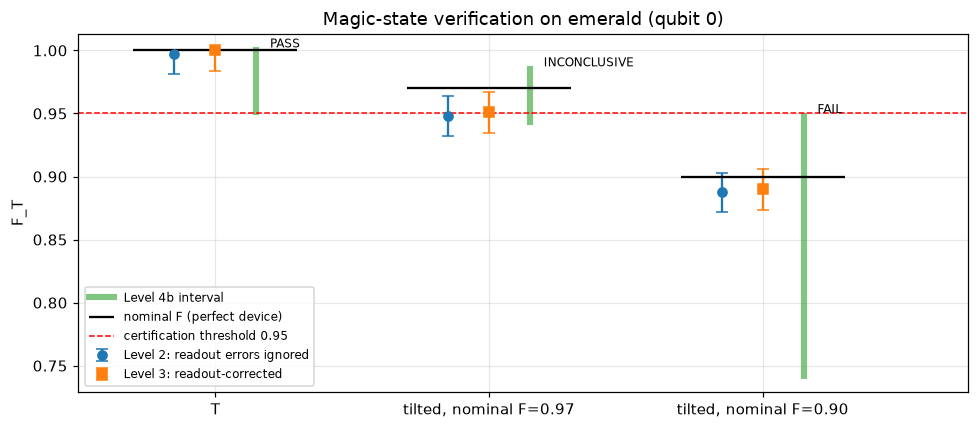

In [20]:
hw_rng = np.random.default_rng(2027)   # separate generator: this section never changes the results above
N_CAL_4B = hw_data["shots"] // 2       # per reference state for Level 4b (all recorded reference shots)
hw_rows = []
for name, delta in hw_data["states"].items():
    F_nom = np.cos(delta / 2) ** 2

    _, l1 = reconstruct_state(HardwareLab(hw_data, name), 2000)
    r_corr = (l1["r_raw"] - hw_beta) / hw_eta                     # undo readout: this amplifies noise by 1/eta,
    r_corr_len = np.linalg.norm(r_corr)                          # so it can leave the Bloch ball again ...
    r_corr_phys = r_corr / max(r_corr_len, 1)                    # ... and gets the same projection as Level 1
    F2, se2 = estimate_fidelity(HardwareLab(hw_data, name), 4000)
    F3, se3, _ = estimate_fidelity_mitigated(HardwareLab(hw_data, name), 4000, 4000)
    l4 = certify(HardwareLab(hw_data, name), max_shots=hw_data["shots"], rng=hw_rng)
    lab4b = HardwareLab(hw_data, name)
    cal = calibrate_for_certification(lab4b, N_CAL_4B)
    l4b = certify(lab4b, alpha=0.04, readout_cal=cal, max_shots=hw_data["shots"], rng=hw_rng)
    hw_rows.append(dict(name=name, F_nom=F_nom, F2=F2, se2=se2, F3=F3, se3=se3, l4=l4, l4b=l4b))

    print(f"=== {name}   (nominal F = {F_nom:.4f}) ===")
    print(f"  Level 1   raw Bloch vector {l1['r_raw'].round(3)}  |r| = {np.linalg.norm(l1['r_raw']):.3f}"
          f"{'  (projected onto the ball)' if l1['projected'] else ''}")
    print(f"            readout-corrected {r_corr_phys.round(3)}  |r| = {min(r_corr_len, 1):.3f}"
          f"{f'  (was {r_corr_len:.3f} before projecting)' if r_corr_len > 1 else ''}")
    print(f"  Level 2   F = {F2:.4f} +/- {1.96 * se2:.4f}   (readout errors ignored)")
    print(f"  Level 3   F = {F3:.4f} +/- {1.96 * se3:.4f}   (readout-corrected)")
    # consistency check with no ground truth: Level 3's F pushed back through the measured readout map
    # should reproduce Level 2's raw number (Level 4b's formula: F_raw = 1/2 + eta (F - 1/2) + beta / sqrt2)
    print(f"            check: Level 3 + measured readout predicts a raw F of {0.5 + hw_eta * (F3 - 0.5) + hw_beta / SQ2:.4f}"
          f" (Level 2 measured {F2:.4f})")
    lo, hi = l4["F_interval"]
    print(f"  Level 4   {l4['decision']:12s} after {l4['shots']:6,d} shots, F in [{lo:.4f}, {hi:.4f}]   (readout errors ignored)")
    lo, hi = l4b["F_interval"]
    print(f"  Level 4b  {l4b['decision']:12s} after {l4b['shots']:6,d} + {2 * N_CAL_4B:,} calibration shots,"
          f" F in [{lo:.4f}, {hi:.4f}]\n")

# Picture: raw vs corrected estimates, and the certification intervals, for each state
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(hw_rows))
bars = lambda F, se: [[1.96 * r[se] for r in hw_rows], [min(1.96 * r[se], 1 - r[F]) for r in hw_rows]]  # cap at F = 1
ax.errorbar(x - 0.15, [r["F2"] for r in hw_rows], yerr=bars("F2", "se2"), fmt="o", capsize=4,
            label="Level 2: readout errors ignored")
ax.errorbar(x, [r["F3"] for r in hw_rows], yerr=bars("F3", "se3"), fmt="s", capsize=4,
            label="Level 3: readout-corrected")
for i, r in enumerate(hw_rows):
    lo, hi = r["l4b"]["F_interval"]
    ax.plot([i + 0.15] * 2, [lo, hi], color="C2", lw=4, alpha=0.6, label="Level 4b interval" if i == 0 else None)
    ax.text(i + 0.2, hi, r["l4b"]["decision"], fontsize=8, va="bottom")
ax.hlines([r["F_nom"] for r in hw_rows], x - 0.3, x + 0.3, colors="k", lw=1.5, label="nominal F (perfect device)")
ax.axhline(0.95, color="red", ls="--", lw=1, label="certification threshold 0.95")
ax.set_xticks(x, [r["name"] for r in hw_rows])
ax.set_xlim(-0.5, len(hw_rows) - 0.25)
ax.set(ylabel="F_T", title=f"Magic-state verification on {hw_data['backend']} (qubit {hw_data['qubit']})")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

### A closer look: where does the real fidelity loss come from?

The levels above each use only part of the data. Here we use **all** recorded shots (10,000 per basis) to get the most precise readout-corrected Bloch vector of each state. We split it into its **length** $|\vec r|$ (1 = pure; shorter means noise) and its **angle** from $+Z$ in the X–Z plane, compared with the angle we asked for ($45^\circ + \delta$). Uncertainties are $\pm 1\sigma$.

In [21]:
print(f"{'state':24s} {'length |r|':>14s} {'angle':>9s} {'intended':>9s} {'over-rotation':>15s} {'F_T':>7s}")
for name, delta in hw_data["states"].items():
    lab, n = HardwareLab(hw_data, name), hw_data["shots"]
    raw = np.array([lab.measure(b, n).mean() for b in "XYZ"])            # every recorded shot
    r = (raw - hw_beta) / hw_eta                                           # undo readout errors
    se = np.sqrt((1 - raw**2) / n) / hw_eta                                # 1-sigma per component
    length = np.linalg.norm(r)
    d_length = np.sqrt(np.sum((r / length * se) ** 2))
    angle = np.degrees(np.arctan2(r[0], r[2]))                             # angle from +Z toward +X
    d_angle = np.degrees(np.hypot(r[2] * se[0], r[0] * se[2]) / (r[0] ** 2 + r[2] ** 2))
    intended = 45 + np.degrees(delta)
    print(f"{name:24s} {length:.3f} +/- {d_length:.3f} {angle:8.2f}° {intended:8.2f}° "
          f"{angle - intended:+7.2f} +/- {d_angle:.2f}° {fidelity_from_xz(r[0], r[2]):7.4f}")

state                        length |r|     angle  intended   over-rotation     F_T
T                        0.996 +/- 0.007    46.39°    45.00°   +1.39 +/- 0.41°  0.9979
tilted, nominal F=0.97   0.990 +/- 0.005    66.68°    64.95°   +1.73 +/- 0.50°  0.9601
tilted, nominal F=0.90   0.997 +/- 0.002    83.81°    81.87°   +1.94 +/- 0.57°  0.8884


### How to read the hardware results
**Data:** IQM Emerald, physical qubit QB1 (index 0), one job of 11 circuits × 10,000 shots (job ID and calibration set saved in `hardware_data/magic_state_hardware.json`). Re-running the notebook replays this file and uses no credits.

- **Same code, real data.** Every number above comes from the Level 1–4 functions, unchanged. The only new piece is `HardwareLab`, which hands them recorded shots instead of simulated ones.
- **Emerald's readout is about 10× better than our Level 3 model.** We measured $e_0 = 0.32\%$ and $e_1 = 0.56\%$, against the $3\%$ and $5\%$ assumed in the simulations. It is still asymmetric in the expected direction ($e_1 > e_0$, because $|1\rangle$ can decay during readout).
- **So on this qubit, readout correction barely matters.** Level 3 moves $\hat F_T$ by only $+0.002$ to $+0.003$, far less than the $\pm 0.016$ statistical error. Every Level 4 decision is the same with and without calibration, and Level 4b's 10,000 calibration shots buy nothing here. With the noisier readout of the Level 3 simulations, calibration was essential.
- **The self-consistency checks pass.**
  - Pushing Level 3's corrected $F$ back through the measured readout map reproduces Level 2's raw $F$ to within 0.0006 for all three states.
  - Every certification decision agrees with its interval.
  - The states come out in the order they were prepared: $|T\rangle$ (PASS) > nominal 0.97 > nominal 0.90 (FAIL).
- **Clear cases are decided quickly.** $|T\rangle$ PASSes after 2,300 shots and the nominal-0.90 state FAILs after 350–450, with or without calibration.
- **The nominal-0.97 state turned out to be a real near-threshold case.** Its Level 3 estimate is $0.951 \pm 0.016$, and with all 10,000 shots per basis it is about $0.960$, so only about 0.01 above the threshold. Both certification tests correctly stop at **INCONCLUSIVE** after their 10,000-shot budget, with intervals ($[0.945, 0.979]$ without and $[0.943, 0.985]$ with calibration) that straddle 0.95. Experiment 8 predicted this: at $F_T = 0.96$, about half the runs were still INCONCLUSIVE even after 30,000 shots.
- **Most of the real error is a small over-rotation, not noise** (the "closer look" table).
  - All three states are rotated **1.4–1.9° further than intended**, each about $3\sigma$ from zero, while their Bloch vectors stay nearly pure ($|\vec r| = 0.99$–$1.00$).
  - For the nominal-0.97 state, the over-rotation alone lowers $F_T$ from 0.970 to about 0.965. The slightly short vector ($|\vec r| = 0.990 \pm 0.005$) accounts for the rest.
  - A single fidelity number can't distinguish this coherent error from random noise; the Bloch vector can. This is a real example of the Summary's "fidelity is one number" limitation.
  - These data can't fully separate preparation errors from errors in the rotations that change the measurement basis.
- **Undoing readout errors amplifies noise** (we divide by $\hat\eta < 1$). Two corrected Bloch vectors landed just outside the ball ($|\hat r| = 1.001$), so Level 1's projection was needed again.

### Caveats specific to hardware
- **SPAM ambiguity:** calibration counts errors in preparing $|1\rangle$ (an X gate, then possible decay) as readout error, which can bias the corrected $F$ upward. Here the whole correction is only $+0.002$ to $+0.003$, so any such bias is smaller still.
- **One snapshot:** this is one job, on one qubit, under one calibration. Each Level 4 decision is a single run, not the 200-run statistics of Experiment 8. Another qubit or another day would give somewhat different numbers.
- **Drift:** all circuits ran in one job, close together in time, so the calibration and state data match. Calibration data from a different day should not be reused.
- **Shared data:** the levels reuse one recorded dataset (no analysis reuses a shot internally), and all three states share one set of calibration shots.

---
# Summary, limitations and attribution

### What each level does
| Level | Mechanism in one line | Main result |
|---|---|---|
| 1 | Average Pauli outcomes → Bloch vector → project into the ball [3] | Error ∝ $1/\sqrt n$; pure states need the projection about half the time |
| 2 | $F_T$ depends only on $r_x + r_z$ → measure only X, Z [4] | 1.5× fewer shots than tomography; RMSE ≈ $0.55/\sqrt N$ |
| 3 | Readout is affine, $\langle P\rangle_\text{obs} = \eta\langle P\rangle + \beta$ → calibrate and invert, delta-method error bars | Bias removed; honest error bars; about 20–50% of budget on calibration |
| 4 | Random X/Z shots = one coin with $p = \tfrac12 + (F_T - \tfrac12)/\sqrt2$ → confidence sequence [6–9] | Valid under optional stopping; PASS/FAIL/INCONCLUSIVE with $\le 5\%$ error |

### Limitations and failure modes (shown above)
- **Small budgets:** normal-approximation error bars (Levels 2–3) under-cover with tens of shots. Level 4 avoids this with exact, anytime-valid methods.
- **SPAM ambiguity:** readout calibration assumes perfect $|0\rangle$/$|1\rangle$ references. Reference-prep errors make the correction **overestimate** $F_T$.
- **Model assumptions:** the same readout channel for all bases, independent shots, and identical copies (no drift). If the source drifts during a long certification, the i.i.d. guarantee no longer applies.
- **Near-threshold states are expensive:** the honest outcome there is INCONCLUSIVE, by design.
- **Fidelity is one number:** it cannot tell coherent from incoherent errors. Level 1 tomography can. The hardware section shows a real case: a 1.4–1.9° over-rotation that only the Bloch vector reveals.
- **Hardware (bonus section):** there is no ground truth on a real device, so those results are checked for self-consistency rather than scored. Real reference-state preparation errors make the SPAM ambiguity a live issue.
- **Randomized basis choice** (Level 4) is slightly less efficient than a fixed 50/50 split when $r_x \ne r_z$ (variance larger by $(r_x - r_z)^2/4$). That is zero for states on the $T$ axis, and it buys exact i.i.d. statistics.

### References
Numbers in square brackets throughout the notebook refer to this list.

1. S. Bravyi & A. Kitaev, *Universal quantum computation with ideal Clifford gates and noisy ancillas*, PRA 71, 022316 (2005). Magic states (Intro, Background).
2. C. Gidney, N. Shutty & C. Jones, *Magic state cultivation: growing T states as cheap as CNOT gates* (2024), and Google Quantum AI's follow-up experimental work. Motivation and the X/Z-plane convention for $|T\rangle$ (Intro, Background).
3. J. Smolin, J. Gambetta & G. Smith, *Efficient method for computing the maximum-likelihood quantum state from measurements with additive Gaussian noise*, PRL 108, 070502 (2012). Projection onto physical states (Level 1).
4. S. Flammia & Y.-K. Liu, *Direct fidelity estimation from few Pauli measurements*, PRL 106, 230501 (2011). Measuring only the relevant Paulis (Level 2).
5. C. Clopper & E. Pearson, *The use of confidence or fiducial limits illustrated in the case of the binomial*, Biometrika 26, 404 (1934). Exact binomial bounds (Level 4b).
6. J. Ville, *Étude critique de la notion de collectif* (1939). Ville's inequality (Level 4).
7. H. Robbins, *Statistical methods related to the law of the iterated logarithm*, Ann. Math. Stat. 41 (1970). Mixture martingales (Level 4).
8. S. Howard, A. Ramdas, J. McAuliffe & J. Sekhon, *Time-uniform, nonparametric, nonasymptotic confidence sequences*, Ann. Stat. 49 (2021). Confidence sequences (Level 4).
9. I. Waudby-Smith & A. Ramdas, *Estimating means of bounded random variables by betting*, JRSS-B (2024). The betting interpretation (Level 4).
10. IQM Resonance, cloud access to IQM quantum computers, https://resonance.iqm.tech, with the IQM Academy tutorial https://www.iqmacademy.com/tutorials/resonance/. Hardware runs (Bonus).
11. IQM, `iqm-client` with Qiskit integration (version 37.0.0), https://pypi.org/project/iqm-client/. Circuit transpilation and job submission (Bonus).

### AI attribution
This notebook's code and explanations were drafted with the help of Claude (Anthropic), as allowed by the challenge rules. The team verified and understood all the concept and code.